# About this Notebook

This is a Python notebook. This is the notebook you'll use to run and create the analysis code on pickle data sets. Pickle files are created and premanufactured from ROOT files from MicroBooNE LAr experiment.

You should have access to: example_neutrino.ipynb, neutrino_function.py, data folder. You are free to modify neutrino_function.py or create your own plotting functions.

**IMPORTANT:** It is strongly recommended that only **one** student of a lab pair should edit this notebook and the files contained within the server directories. This is because both students cannot see the same live edit of the notebook or files at the same time, and it is easy to accidently overwrite each other.

Code that is commented out with two hashtags should be uncommented when in use.

# All imports

The basic libraries, you may import more if there are present on the server's environment. If you dont have these packages installed on your local machine, you can use **pip install X** or **pip3 install X** to start using them.

In [1]:
import numpy as np
import pickle

import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import Neutrino_functions

from math import *
import scipy as sci

# MACHINE LEARNING IMPORTS
import sklearn
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn import set_config

set_config(display="text")

from scipy.stats import chi2, norm

# Opening the MC and data frames

In [2]:
# MC
MC_file = './data/MC_EXT_flattened.pkl'

# Data
data_file = './data/data_flattened.pkl'


# Open file as pandas dataframe
MC_EXT = pd.read_pickle(MC_file)
data = pd.read_pickle(data_file)

# removing 'Subevent' from data
MC_EXT = MC_EXT.drop('Subevent', axis = 1)
data = data.drop('Subevent', axis = 1)

# You can display the dataframe by uncommenting these lines and running the cell

In [3]:
# Uncomment these lines to display the dataframes
pd.set_option('display.max_columns', 100)
# displays top 10 results.
data.head(10)

,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v
0,48.170196,230.178085,0.289455,0,0.932121,662.713745,-10.419758,0.564317,1.0,0.981798,443.558472,-71.411057,32.10228,32.137272,-71.675980,443.439148,10000.021584,0.624387,0.672995
1,48.170196,19.862617,20.065849,0,0.932121,467.605438,-41.015533,40.286861,0.460725,0.722245,455.0065,-55.723381,36.461731,32.137272,-71.675980,443.439148,10000.021584,0.145945,0.159
2,177.083498,174.338699,0.057629,0,0.588847,978.765259,9.115969,153.437668,0.999995,0.970214,852.828674,-36.029785,42.856102,42.869896,-35.978130,852.848938,0.629191,0.502137,0.551996
3,0.067737,264.553223,196.515564,0,0.002079,998.799072,18.552534,225.164139,1.0,0.977688,797.282776,63.213791,63.001648,160.463943,-113.297066,772.441833,10000.778217,0.700354,0.627999
4,36.361293,493.096283,0.465464,0,0.983048,865.795166,-56.678547,80.313004,1.0,0.990403,408.639801,96.316406,141.032898,141.039246,96.385994,408.178772,1.296849,1.220361,1.124005
5,127.613429,181.327194,0.272344,0,0.021950,264.979065,92.158607,255.202988,0.999972,0.958479,230.559982,-81.870941,221.46637,221.349503,-81.868439,230.311829,9999.794868,0.517367,0.527997
6,127.613429,10.863928,0.334015,0,0.021950,226.903671,-91.896515,218.480057,0.791141,-0.287616,229.998383,-81.993217,221.4086,221.349503,-81.868439,230.311829,9999.794868,0.114687,0.102
7,101.562292,8.869122,265.905823,0,0.036152,110.97657,81.228905,30.3652,0.011572,0.133134,114.274597,86.827835,36.310745,170.431870,59.736755,340.503021,9999.221455,0.106222,0.101
8,181.173178,168.925873,0.349405,0,0.517549,517.184326,67.922836,156.103348,0.999998,0.959285,406.7724,114.33268,40.269585,40.016575,114.483635,406.585693,9999.828041,0.490352,0.428998
9,162.177990,47.523987,0.030297,0,0.336266,892.599304,-59.251465,37.77512,0.93185,0.761358,870.96521,-33.337875,71.00219,71.004707,-33.363049,870.948181,0.286233,0.220104,0.228


In [4]:
MC_EXT.head(10)

,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v,weight,true_E,true_L,true_muon_mom
0,124.478148,225.284348,1.286398,21,0.994485,510.146088,-19.997118,191.864334,1.0,0.977081,343.433655,35.865448,54.776821,53.900658,36.203041,342.578735,1.164239,0.613618,0.624997,0.000002,1.371928,438.602722,0.607686
1,124.478148,7.850903,131.947891,21,0.994485,389.239197,46.669083,183.160797,0.041434,0.486446,382.998871,47.109879,178.486572,53.900658,36.203041,342.578735,1.164239,0.101568,0.093,0.000002,1.371928,438.602722,0.607686
2,141.086923,251.017548,0.025229,5,0.007706,766.055969,-50.159794,172.77446,1.0,0.972468,658.480286,117.427391,20.797407,20.804905,117.408989,658.495789,9999.989363,0.670372,0.740995,0.158957,1.798278,440.984772,0.727932
3,10.511966,58.736591,10.511966,4,0.066952,213.629105,117.414757,88.746597,0.929871,0.870984,224.018387,60.914005,78.242538,78.443840,50.530334,223.597870,9999.441230,0.246837,0.234,0.192390,0.777679,438.613037,0.489567
4,10.511966,9.962337,3.888895,4,0.066952,235.423004,46.921162,80.265305,0.372258,0.404711,226.829147,51.903919,80.192444,78.443840,50.530334,223.597870,9999.441230,0.11096,0.131,0.192390,0.777679,438.613037,0.489567
5,147.929810,289.265442,0.152002,5,0.515178,1031.704712,52.0289,83.527153,1.0,0.9848,761.951172,-6.10771,1.388844,1.357146,-6.141214,761.806335,9999.934871,0.755327,0.761996,0.986006,1.214413,431.785278,0.826329
6,96.691013,56.727428,27.846855,21,0.998477,1036.508911,-38.234692,19.931959,0.065278,0.902933,992.340698,-65.519211,22.75659,25.337120,-80.776207,969.163696,10000.275867,0.242116,0.188,0.158957,1.857195,463.048309,1.271057
7,96.691013,67.758522,0.264366,21,0.998477,1036.692261,-78.989571,24.593576,0.966078,0.940751,969.034668,-81.002808,25.39159,25.337120,-80.776207,969.163696,10000.275867,0.267746,0.346999,0.158957,1.857195,463.048309,1.271057
8,96.691013,25.262609,7.398347,21,0.998477,987.487305,-65.503288,5.5114,0.082593,0.79802,972.884705,-76.234444,20.853903,25.337120,-80.776207,969.163696,10000.275867,0.161958,0.099,0.158957,1.857195,463.048309,1.271057
9,106.679589,73.540779,0.226748,5,0.040650,769.010193,110.767021,45.539276,0.950805,0.911611,759.31604,53.225922,1.124355,1.250130,53.412140,759.350220,9999.371950,0.280941,0.384999,0.194167,0.890958,445.648376,0.478177


In [5]:
MC_EXT.info()

<class 'pandas.DataFrame'>
RangeIndex: 555624 entries, 0 to 555623
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   _closestNuCosmicDist  555624 non-null  float64
 1   trk_len_v             555624 non-null  object 
 2   trk_distance_v        555624 non-null  object 
 3   category              555624 non-null  int64  
 4   topological_score     555624 non-null  float32
 5   trk_sce_end_z_v       555624 non-null  object 
 6   trk_sce_end_y_v       555624 non-null  object 
 7   trk_sce_end_x_v       555624 non-null  object 
 8   trk_score_v           555624 non-null  object 
 9   trk_llr_pid_score_v   555624 non-null  object 
 10  trk_sce_start_z_v     555624 non-null  object 
 11  trk_sce_start_y_v     555624 non-null  object 
 12  trk_sce_start_x_v     555624 non-null  object 
 13  reco_nu_vtx_sce_x     555624 non-null  float32
 14  reco_nu_vtx_sce_y     555624 non-null  float32
 15  reco_nu_vtx

# Machine learning for Particle Classification

First, look at a sub-sample of our Monte Carlo data.

In [6]:
# Reduce the amount of data for visualisation purposes
MC_EXT_VIS = MC_EXT.sample(int(len(MC_EXT)/10))

# Resetting the index
MC_EXT_VIS.reset_index(drop=True, inplace=True)

# Removing high energy (unphysical) monte carlo results
MC_EXL_VIS = MC_EXT_VIS.drop(MC_EXT_VIS[MC_EXT_VIS.trk_energy_tot > 2].index, inplace = True)

# Resetting the index again
MC_EXT_VIS.reset_index(drop=True, inplace=True)

# Displaying dataframe
print("Length of new data sample: {}".format(len(MC_EXT_VIS)))
MC_EXT_VIS.head(20)


Length of new data sample: 14421


,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v,weight,true_E,true_L,true_muon_mom
0,9.577207,132.207397,3.677672,21,0.995558,370.040344,35.221996,216.284256,0.999986,0.833157,310.54834,90.473946,115.013275,114.106613,93.905937,310.141205,1.565972,0.41051,0.344999,0.158957,1.925911,444.891602,0.289217
1,0.090171,149.772217,0.090171,7,0.009248,690.015747,-42.608738,142.907654,0.999994,0.967028,668.435974,104.15744,124.708855,124.758598,104.236069,668.447021,0.556073,0.448705,0.527997,0.257732,1.000000,0.000000,0.000000
2,142.529041,13.558231,0.925402,7,0.052663,231.216125,80.559677,18.434603,0.897599,0.62943,226.74585,68.934685,13.172913,12.809541,68.186775,226.343277,0.218452,0.12502,0.137,0.257732,1.000000,0.000000,0.000000
3,191.436331,69.756546,1.093873,21,0.481427,817.277832,-20.276354,138.234497,0.991883,0.908693,783.609741,30.53812,105.622353,106.525574,29.976376,783.561096,0.400766,0.272321,0.242,0.221527,0.426568,455.962555,0.267659
4,192.249364,37.206886,2.086914,21,0.979109,211.307877,-80.249527,79.196861,0.956458,0.018005,175.249176,-87.745186,83.41684,83.495094,-86.820755,173.396332,0.616287,0.194365,0.199,0.158957,1.003255,440.674835,0.299533
5,109.244181,83.398399,0.406013,21,0.774284,985.630493,-16.643902,28.288967,0.873311,0.791073,971.83197,-12.038404,110.241982,110.631165,-12.135169,971.802551,0.471052,0.303169,0.392998,0.220086,0.499141,468.187866,0.303668
6,111.467947,186.335251,1.411539,7,0.047990,826.266357,58.859104,39.984585,1.0,0.90739,909.918579,-91.983849,33.62056,33.720291,-93.197495,909.166809,0.730197,0.528293,0.466998,0.257732,1.000000,0.000000,0.000000
7,77.762415,25.650068,8.767199,21,0.784464,280.69162,-86.176636,100.428825,0.058288,0.703561,291.889069,-68.363113,87.101456,84.265465,-60.407585,295.241547,0.981870,0.16307,0.111,0.158957,0.955346,449.372742,0.518009
8,179.931524,147.409882,0.211264,21,0.073070,691.319946,-14.833096,159.290466,0.999986,0.962138,613.053772,-92.144745,62.618107,62.497410,-92.246117,612.918945,0.544983,0.443571,0.420998,0.158957,1.048555,444.340637,0.433786
9,282.028805,139.79538,0.099709,31,0.364991,421.358704,40.675625,85.13649,0.99879,0.964781,294.272095,94.668411,104.889168,104.843575,94.739861,294.226624,0.488522,0.427017,0.546996,0.158957,0.914251,424.212250,NaN


# Exercise 5 Data Visualisation
Lets visualise some of the variables using *seaborn*

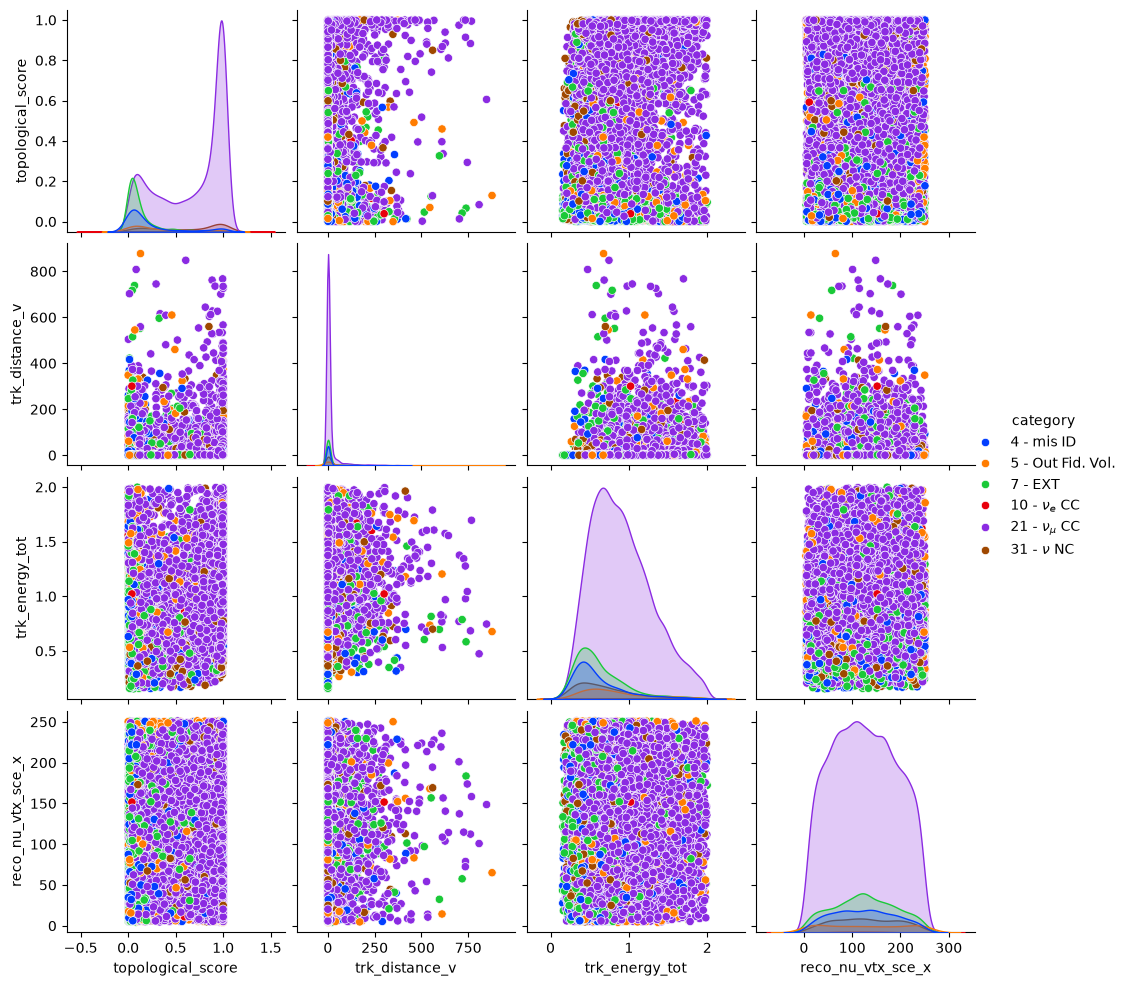

In [7]:
# Visualising a couple of variables.
variable_list = ['category', 'topological_score', 'trk_distance_v', 'trk_energy_tot', 'reco_nu_vtx_sce_x']

# List of categories in text
ptype = [r"mis ID", r"Out Fid. Vol.", r"EXT", r"$\nu_e$ CC", r"$\nu_{\mu}$ CC", r"$\nu$ NC"]

# Keep category colours identical in both pairplots.
category_palette = dict(zip([4, 5, 7, 10, 21, 31], sns.color_palette('bright', 6)))

# Plot data
fig = sns.pairplot(MC_EXT_VIS[variable_list], hue = 'category', palette = category_palette)

# Change location of legend
fig._legend.set_bbox_to_anchor((1.05, 0.5))

# Add Category number and type to legend
for t, l in zip(fig._legend.texts, ptype):
   t.set_text(str(t.get_text()) + " - " + str(l))

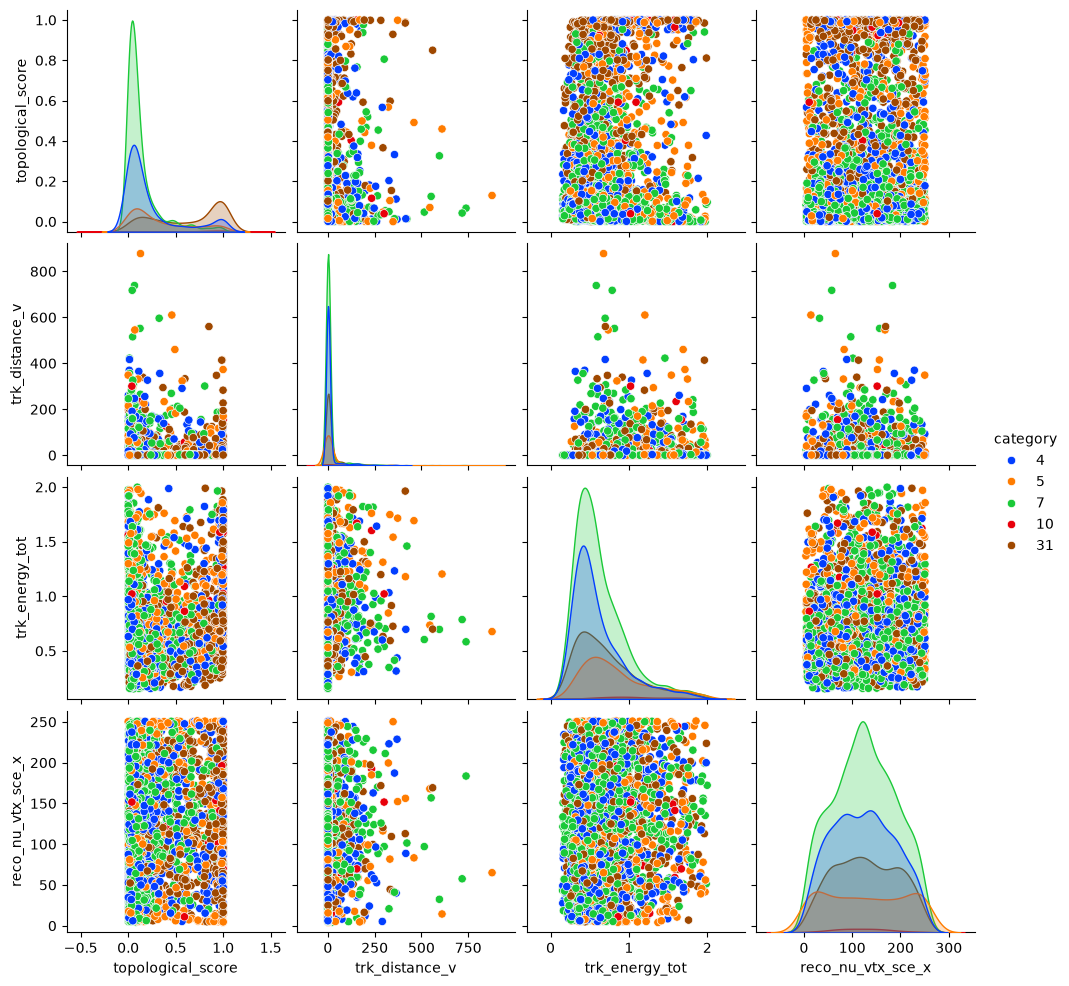

In [8]:
MC_EXT_VIS_background = MC_EXT_VIS.copy(deep=True)

MC_EXT_VIS_background = MC_EXT_VIS_background[
    MC_EXT_VIS_background['category'] != 21
]

sns.pairplot(
    MC_EXT_VIS_background[variable_list],
    hue='category',
    palette=category_palette
)

In [9]:
# Plot your background events using sns.pairplot

# List of categories (excluding signal) in text
ptype_no_mu = [r"mid ID", r"Out Fid. Vol.", r"EXT", r"$\nu_e$ CC", r"$\nu$ NC"]


In [10]:
# Make sure to delete dataframe copies if you no longer need them!
del MC_EXT_VIS

### Exercise 5: Background trends and visualisation

Removing category 21 makes the background distributions easier to inspect. Compare where each category concentrates in topological score, distance to the vertex, reconstructed energy and vertex position. Describe the trends visible in your plots; apparent separation does not by itself establish a correlation or a reliable selection cut.

Trends can still be difficult to see because points overlap, category sizes differ, extreme values stretch the axes, and useful relationships may involve more than two variables. Smaller transparent markers and an equal-sized sample from each background category help compare shapes. Equal sampling changes the relative category counts, so this sample is for visualisation only, not for energy spectra, purity or efficiency calculations.


### Bonus 1: Make background patterns clearer

Use up to 1,000 rows per category, taking the same number from every category. A fixed random seed makes this visualisation reproducible. Keep the original background dataframe unchanged and retain the original category colours.


Rows per category in the visualisation sample:
category
4     29
5     29
7     29
10    29
31    29
Name: count, dtype: int64


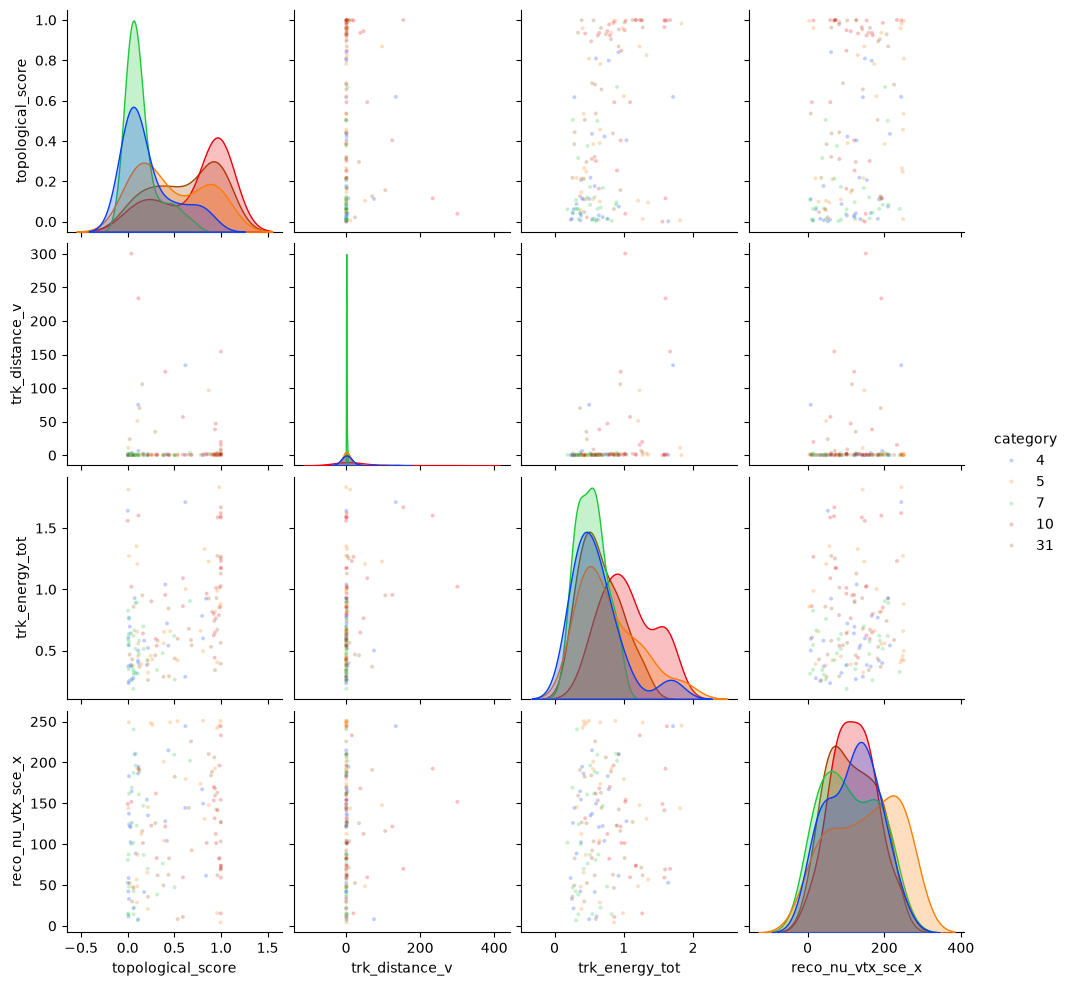

In [11]:
# Create a balanced sample for visualisation only.
background_counts = MC_EXT_VIS_background['category'].value_counts()
rows_per_category = min(1000, int(background_counts.min())) if not background_counts.empty else 0

if rows_per_category == 0:
    raise ValueError('No background rows available. Run the preceding Exercise 5 cells first.')

background_balanced = pd.concat([
    group.sample(n=rows_per_category, random_state=1)
    for _, group in MC_EXT_VIS_background.groupby('category', sort=True)
], ignore_index=True)

print('Rows per category in the visualisation sample:')
print(background_balanced['category'].value_counts().sort_index())

background_variables = [name for name in variable_list if name != 'category']
fig_background_clear = sns.pairplot(
    background_balanced[background_variables + ['category']],
    vars=background_variables,
    hue='category',
    palette=category_palette,
    diag_kind='kde',
    plot_kws={'s': 8, 'alpha': 0.25},
    diag_kws={'fill': True, 'alpha': 0.25, 'warn_singular': False}
)
plt.show()


### Bonus 2: Explore additional variables

Add track length, track/shower score and the particle-identification score. Track length may distinguish different track populations; the track score describes whether an object looks track-like rather than shower-like; the PID score helps distinguish particle hypotheses such as muons and protons. Compare their distributions and pairwise relationships across background categories. Record which categories overlap and whether the added variables reveal clearer separation.


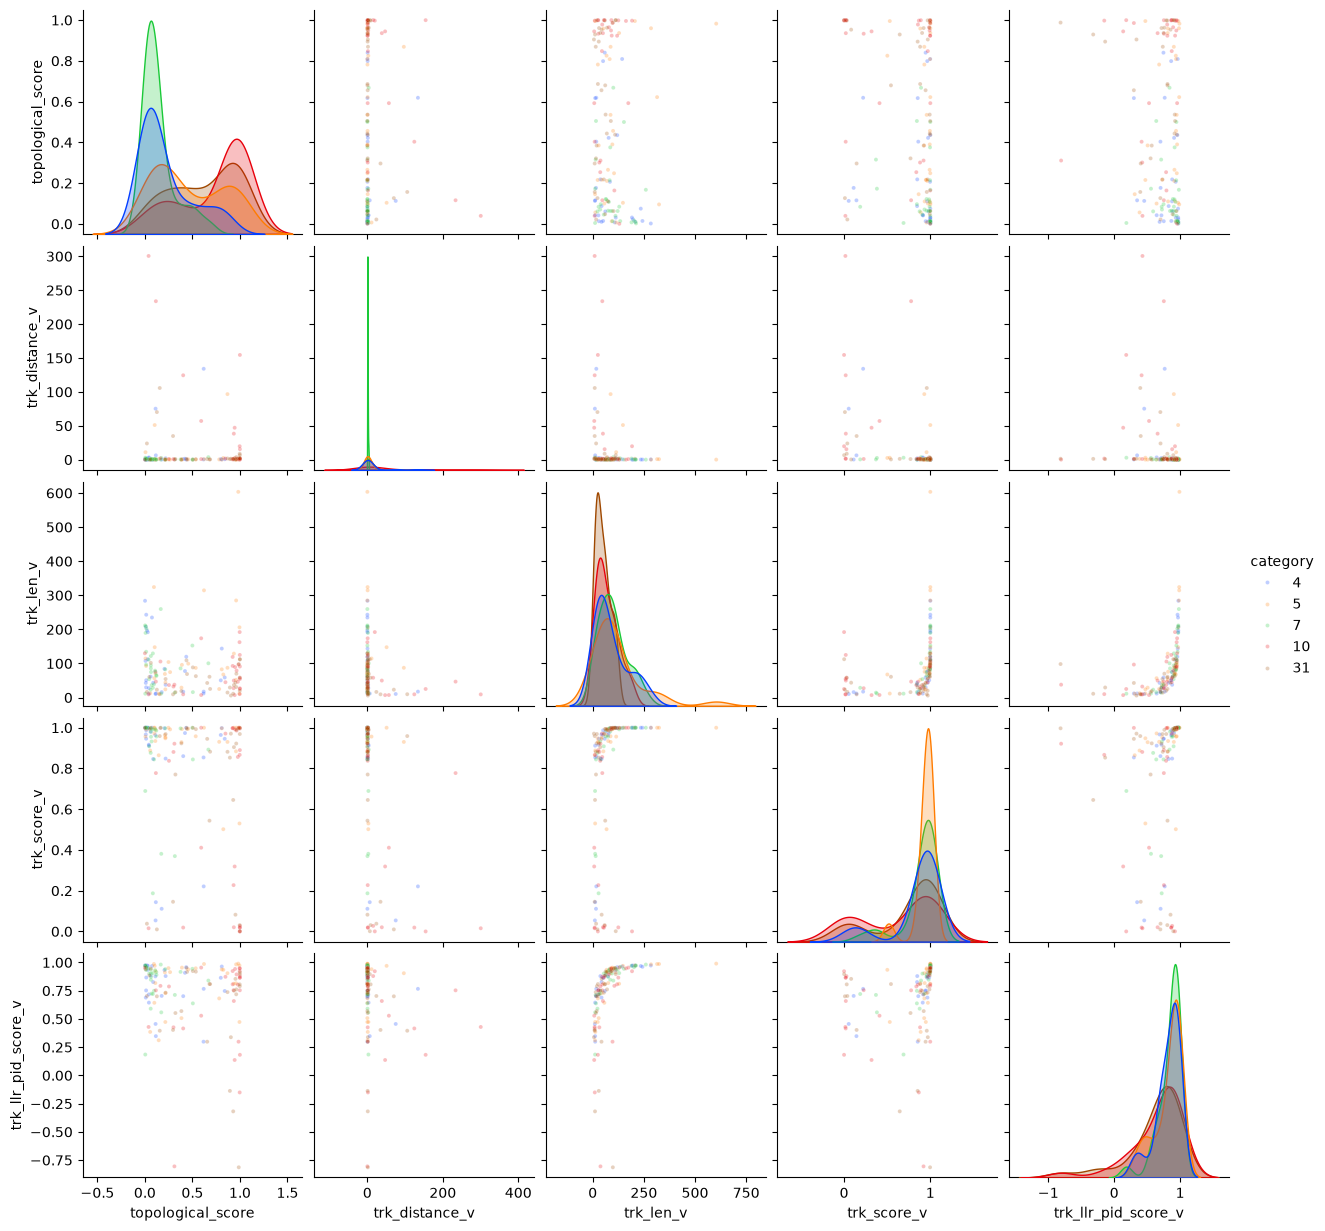

In [12]:
extra_variables = [
    'topological_score',
    'trk_distance_v',
    'trk_len_v',
    'trk_score_v',
    'trk_llr_pid_score_v'
]

fig_background_extra = sns.pairplot(
    background_balanced[extra_variables + ['category']],
    vars=extra_variables,
    hue='category',
    palette=category_palette,
    diag_kind='kde',
    plot_kws={'s': 8, 'alpha': 0.25},
    diag_kws={'fill': True, 'alpha': 0.25, 'warn_singular': False}
)
plt.show()


# Exercise 6: Random Forest applications

Here we shall modify the shape of our data for its usage in a decision tree, then apply the *RandomForest* method from the skikit-learn package.

In [13]:
# Adjust data shape
features = ['_closestNuCosmicDist', 'trk_len_v', 'trk_distance_v', 'topological_score', 'trk_sce_end_z_v', 'trk_sce_end_y_v', 'trk_sce_end_x_v', 'trk_score_v', 'trk_llr_pid_score_v', 'trk_sce_start_z_v', 'trk_sce_start_y_v', 'trk_sce_start_x_v', 'reco_nu_vtx_sce_x', 'reco_nu_vtx_sce_y', 'reco_nu_vtx_sce_z', 'trk_energy_tot']
output = ['category']

# Setup new database, NEED MORE VALUES
MC_EXT_ML = MC_EXT.copy(deep = True)
MC_EXT_ML = MC_EXT.sample(int(len(MC_EXT)/10))


# Remove muon neutrino and electron neutrino events.
MC_EXT_ML = MC_EXT_ML[~MC_EXT_ML['category'].isin([10, 21])].copy()

# Print length of dataframe,, with length N
print("Length of MC dataframe: ", len(MC_EXT_ML))

Length of MC dataframe:  31714


In [14]:
from sklearn.preprocessing import StandardScaler

# Setting up input parameters for random forest.
X = MC_EXT_ML[features]
y = np.array(MC_EXT_ML['category'])

# Display shape of X and y, should be (N, 16) (N) where is number of samples.
print("(X) (y) shape:")
print(X.shape, y.shape)

# Then split the data up into a "training set" and "test set" using train_test_split.
# Keep the random_state=1 in your arguments
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y) # 80/20 training/test split

# Balance training classes by randomly undersampling to the smallest class.
# Keep the test set and the original physics samples at their natural proportions.
training_labels = pd.Series(y_train).reset_index(drop=True)
training_counts = training_labels.value_counts().sort_index()
if set(training_counts.index) != {4, 5, 7, 31}:
    raise ValueError('Expected all four background classes: 4, 5, 7 and 31.')
rows_per_class = int(training_counts.min())
balanced_positions = np.concatenate([
    training_labels[training_labels.eq(category)].sample(
        n=rows_per_class, random_state=1
    ).index.to_numpy()
    for category in training_counts.index
])
# Shuffle selected positions while preserving feature-label alignment.
balanced_positions = np.random.default_rng(1).permutation(balanced_positions)
x_train = x_train.iloc[balanced_positions].copy()
y_train = np.asarray(y_train)[balanced_positions]
print('Training class counts before balancing:')
print(training_counts.to_string())
print('Training class counts after balancing:')
print(pd.Series(y_train).value_counts().sort_index().to_string())

# Standardise features using training-set statistics only.
# Apply the same transformation to the test set; keep category labels unchanged.
scaler = StandardScaler()
x_train = pd.DataFrame(
    scaler.fit_transform(x_train), columns=features, index=x_train.index
)
x_test = pd.DataFrame(
    scaler.transform(x_test), columns=features, index=x_test.index
)

# Print the shape, should now be 
print("\n(x_train) (y_train) shape: ")
print(x_train.shape, y_train.shape)

print("\n(x_test) (y_test) shape: ")
print(x_test.shape, y_test.shape)


(X) (y) shape:
(31714, 16) (31714,)
Training class counts before balancing:
4      4127
5      7578
7     10712
31     2954
Training class counts after balancing:
4     2954
5     2954
7     2954
31    2954

(x_train) (y_train) shape: 
(11816, 16) (11816,)

(x_test) (y_test) shape: 
(6343, 16) (6343,)


Produce your randomforest model and fit it (dont worry, there is no explicit output, but make sure you haven't made your model too big! It shouldn't take any more than a couple of minutes at most to fit).

In [15]:
# Produce randomforest classifier model and fit to training data
# Keep the random_state=1 in your arguments
rf = RandomForestClassifier(random_state=1, n_estimators=1000, max_depth=8, min_samples_split=5, min_samples_leaf=2,
                           criterion='gini', n_jobs=-1)

# Fitting takes the input and "truth" data for classification purposes
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=8, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=1000, n_jobs=-1, random_state=1)

Test the accuracies of your results:

In [16]:
# Produce predictions for the classification of your training dataset using your model:
y_pred = rf.predict(x_train)

# plot the accuracies of said predictions
print("Accuracy on training dataset:",metrics.accuracy_score(y_train, y_pred))
rf_acc_train = metrics.accuracy_score(y_train, y_pred)
y_pred = rf.predict(x_test)
print("Accuracy on testing dataset:",metrics.accuracy_score(y_test, y_pred))
rf_acc_test = metrics.accuracy_score(y_test, y_pred)

Accuracy on training dataset: 0.6773019634394042
Accuracy on testing dataset: 0.5830048872773136


If your training accuracy is similar to your testing accuracy, this demonstrates that you haven't overfit your data!

#### Confusion matrix and variable importance

Produce a confusion matrix for your model to quantify its ability to predict your different interaction types.

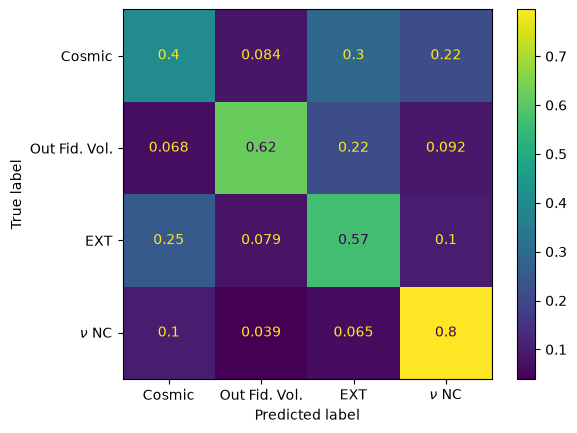

In [17]:
# For labelling your confusion matrix
ptype_no_mu_e = [r"Cosmic", r"Out Fid. Vol.", r"EXT", r"$\nu$ NC"]

# plot your confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[4, 5, 7, 31], normalize = 'true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ptype_no_mu_e)
disp.plot()
plt.show()

Plot the importance of your different parameters.

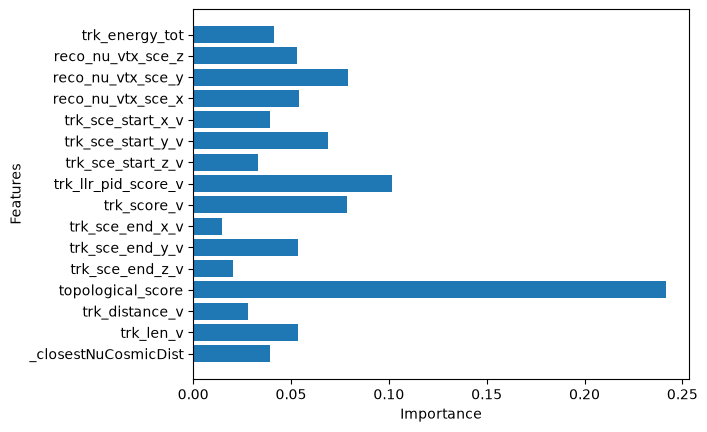

In [18]:
# Plot importance
importance = rf.feature_importances_
ytix = features

plt.barh(range(16), importance)
plt.yticks(range(16), features)
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()


# Neutrino_functions.py

You are given access to a couple of template functions provided within Neutrino_functions.py, which may be helpful in completing this lab. One such function is 'Neutrino_functions.histogram_plot', which can be seen below, but you can create your own functions if you wish.

In [19]:
#This command shows what input you should give the plotting function. The inputs with =None can be left out when calling the function
help(Neutrino_functions.histogram_plot)

Help on function histogram_plot in module Neutrino_functions:

histogram_plot(
    MC_frame,
    variable,
    bins,
    name,
    scaling,
    xlims=[],
    plot_fig=True,
    plot_data=False,
    logscale=None,
    dataFrame=None,
    Stat_func=None
)
    MC_frame: pandas dataframe - MC dataframe
    variable: string - name of the variable
    bins: int - number of bins
    name: string - name of the plot. The plot is saved
    scaling: array/list - weights you want to apply on MC data
    plot_data: boolean - if True then plots data as well
    logscale: boolean - if True then y axis is log scale
    dataFrame: pandas dataframe - data dataframe



# Exercise 7: Selection cuts and histogram plotting

Following Labbook p.12, inspect MC distributions by category, choose physically motivated cuts and apply the same `Selections` function to MC and real data. Category 21 is the muon-neutrino CC signal; 4, 5, 7, 10 and 31 are backgrounds.

All cuts use original physical units. No feature standardisation, class balancing or random-forest retraining is needed here. The previous Ex7 exploration, including its random forests and confusion matrices, is preserved in `../analysis_work/MainAnalysis_before_Ex7_revision.ipynb`.

The cuts below are transparent starting choices, not prescribed Labbook values or an established optimum. Ex8 will study their purity-efficiency trade-off.

In [20]:
# Use fresh uncut samples: rerunning Ex7 must not apply cuts cumulatively.
MC_EXT_original = pd.read_pickle(MC_file).drop(columns=['Subevent'], errors='ignore')
data_original = pd.read_pickle(data_file).drop(columns=['Subevent'], errors='ignore')
category_order = [4, 5, 7, 10, 21, 31]
category_palette = dict(zip(category_order, sns.color_palette('bright', 6)))
category_names = {4: 'Mis-ID', 5: 'Out Fid. Vol.', 7: 'EXT',
                  10: 'Electron neutrino CC', 21: 'Muon neutrino CC (signal)',
                  31: 'Neutrino NC'}

# Chosen in physical units from the MC distributions; adjustable for Ex8.
energy_upper_cut = 2.0  # GeV
fiducial_bounds = {'reco_nu_vtx_sce_x': (20.0, 235.0),
                   'reco_nu_vtx_sce_y': (-100.0, 100.0),
                   'reco_nu_vtx_sce_z': (20.0, 1000.0)}  # cm
minimum_topological_score = 0.20

print(f'Uncut MC rows: {len(MC_EXT_original):,}; data rows: {len(data_original):,}')


Uncut MC rows: 555,624; data rows: 119,970


### 1. Inspect the reconstructed energy and remove its high-energy tail
The Labbook suggests an upper limit of a couple of GeV. Use `E < 2 GeV` as an initial analysis range, identically for MC and data. The full-range panel shows the tail; the zoomed panel shows the region retained. A display limit is not a further selection.

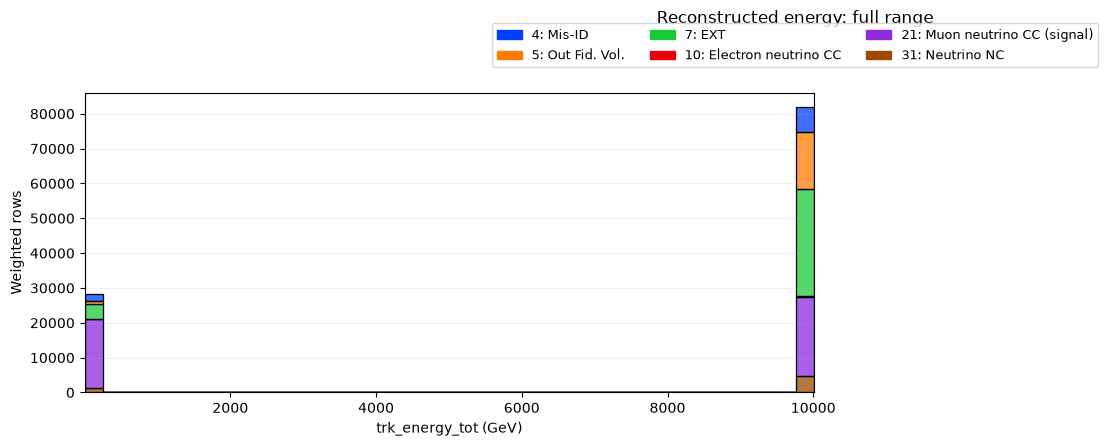

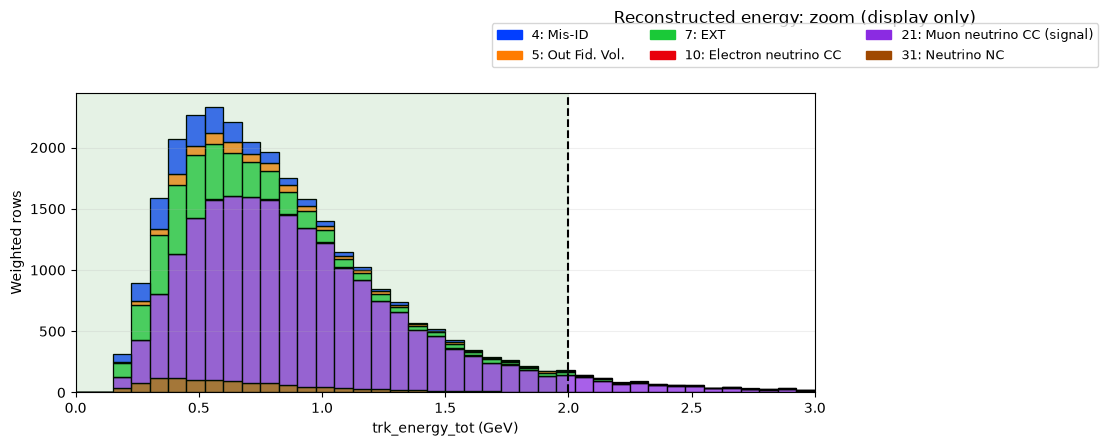

After E < 2 GeV: MC 144,211; data 28,808


In [21]:
def plot_category_histograms(frame, variables, ranges=None, title='', cut_ranges=None):
    """Weighted category yields, with shared bins; no class equalisation."""
    ranges = ranges or {}
    cut_ranges = cut_ranges or {}
    ncols = 2
    nrows = (len(variables) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5*nrows), squeeze=False)
    for ax, variable in zip(axes.flat, variables):
        values = pd.to_numeric(frame[variable], errors='coerce')
        finite = np.isfinite(values)
        if not finite.any():
            ax.set_title(variable + ': no finite values')
            continue
        limits = ranges.get(variable, (float(values[finite].min()), float(values[finite].max())))
        if limits[0] == limits[1]:
            limits = (limits[0] - 0.5, limits[1] + 0.5)
        sns.histplot(data=frame.loc[finite], x=variable, hue='category',
                     hue_order=category_order, palette=category_palette,
                     weights='weight', multiple='stack', bins=40,
                     binrange=limits, ax=ax)
        ax.set_xlim(*limits)
        ax.set_xlabel(variable + (' (GeV)' if variable == 'trk_energy_tot' else
                                 ' (cm)' if variable.startswith(('reco_', 'trk_sce_')) or
                                 variable in ['trk_len_v', 'trk_distance_v', '_closestNuCosmicDist'] else ''))
        ax.set_ylabel('Weighted rows')
        legend = ax.get_legend()
        if legend is not None:
            for text in legend.get_texts():
                category = int(text.get_text())
                text.set_text(f'{category}: {category_names[category]}')
            legend.remove()
        if variable in cut_ranges:
            low, high = cut_ranges[variable]
            left = limits[0] if low is None else low
            right = limits[1] if high is None else high
            ax.axvspan(max(left, limits[0]), min(right, limits[1]), color='green', alpha=0.10)
            for bound in (low, high):
                if bound is not None:
                    ax.axvline(bound, color='black', linestyle='--')
        ax.grid(axis='y', alpha=0.2)
    for ax in axes.flat[len(variables):]:
        ax.set_visible(False)
    fig.suptitle(title)
    handles = [mpatches.Patch(color=category_palette[c], label=f'{c}: {category_names[c]}') for c in category_order]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.965), ncol=3, fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

plot_category_histograms(MC_EXT_original, ['trk_energy_tot'],
                         title='Reconstructed energy: full range',
                         cut_ranges={'trk_energy_tot': (None, energy_upper_cut)})
plot_category_histograms(MC_EXT_original, ['trk_energy_tot'],
                         ranges={'trk_energy_tot': (0, 3)},
                         title='Reconstructed energy: zoom (display only)',
                         cut_ranges={'trk_energy_tot': (None, energy_upper_cut)})

def energy_selection(frame):
    values = pd.to_numeric(frame['trk_energy_tot'], errors='coerce')
    return frame.loc[np.isfinite(values) & values.lt(energy_upper_cut)].copy()

MC_EXT_energy_selected = energy_selection(MC_EXT_original)
data_energy_selected = energy_selection(data_original)
print(f'After E < {energy_upper_cut:g} GeV: MC {len(MC_EXT_energy_selected):,}; '
      f'data {len(data_energy_selected):,}')


### 2. Inspect every input variable after the energy cut
The following plots include all 16 Ex6 features and the two reconstructed muon momenta in Labbook Table 2. MC categories retain their natural weighted proportions. Axis ranges below are display choices only, used to expose the populated region without letting extreme values compress it. All finite rows are still considered by `Selections`.

Dashed lines and green shading show the proposed retained ranges. Coordinate cuts use both a lower and an upper boundary. Start/end coordinates are inspected but not automatically required to be contained: a vertex cut and a full-track containment requirement are different selections.

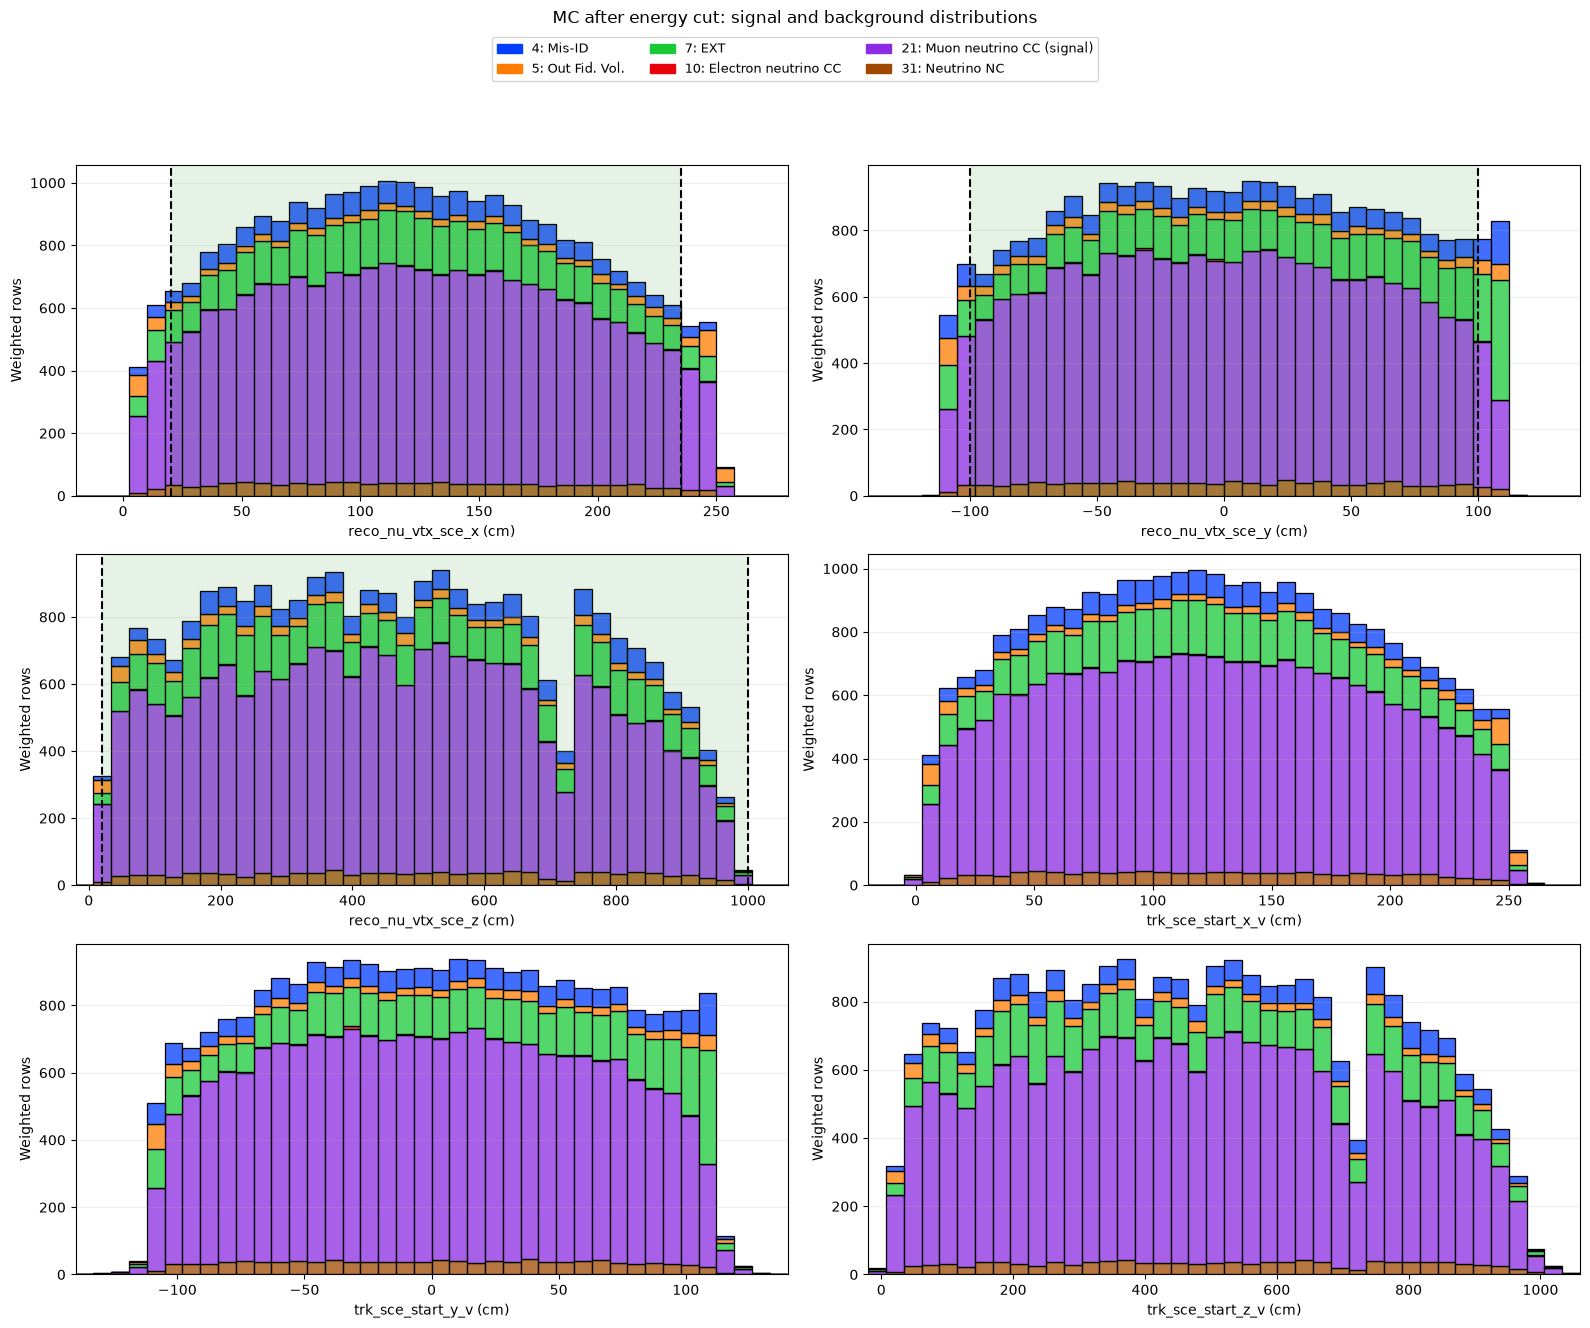

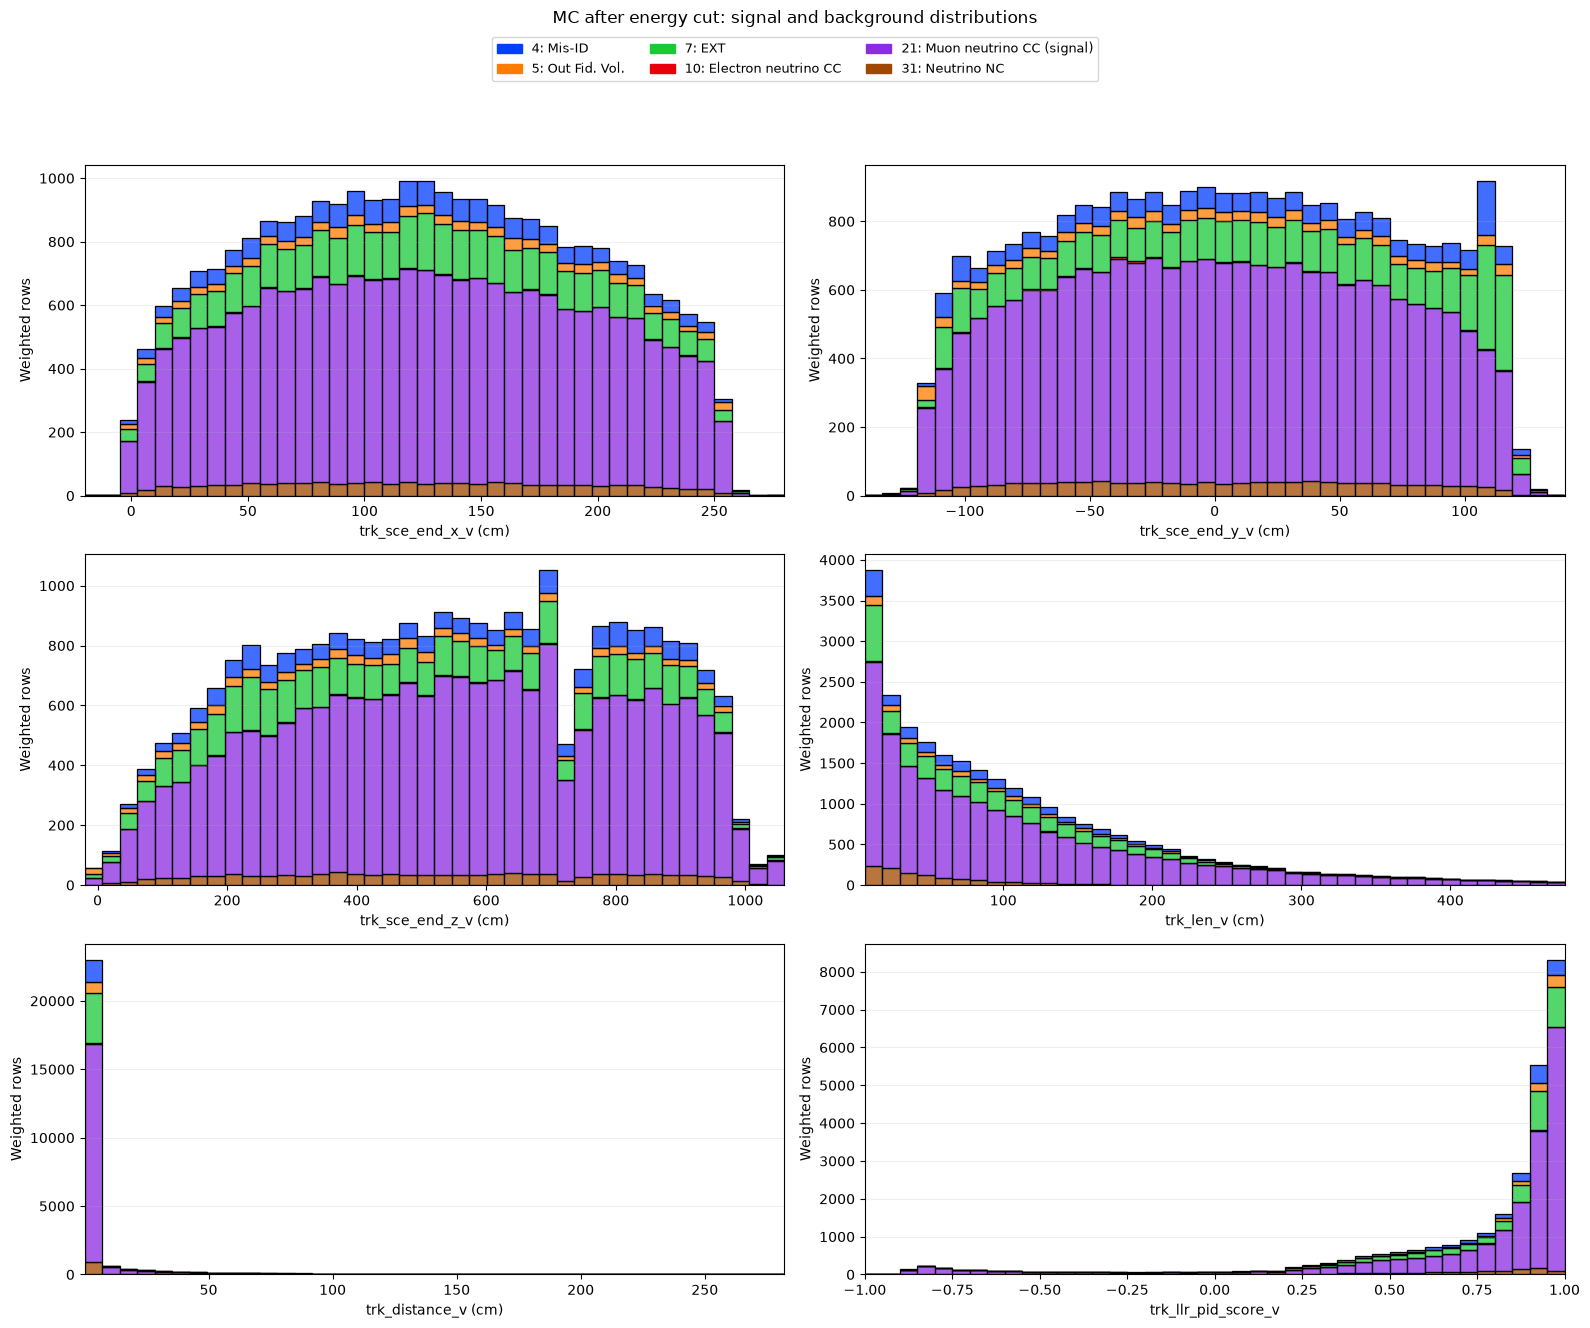

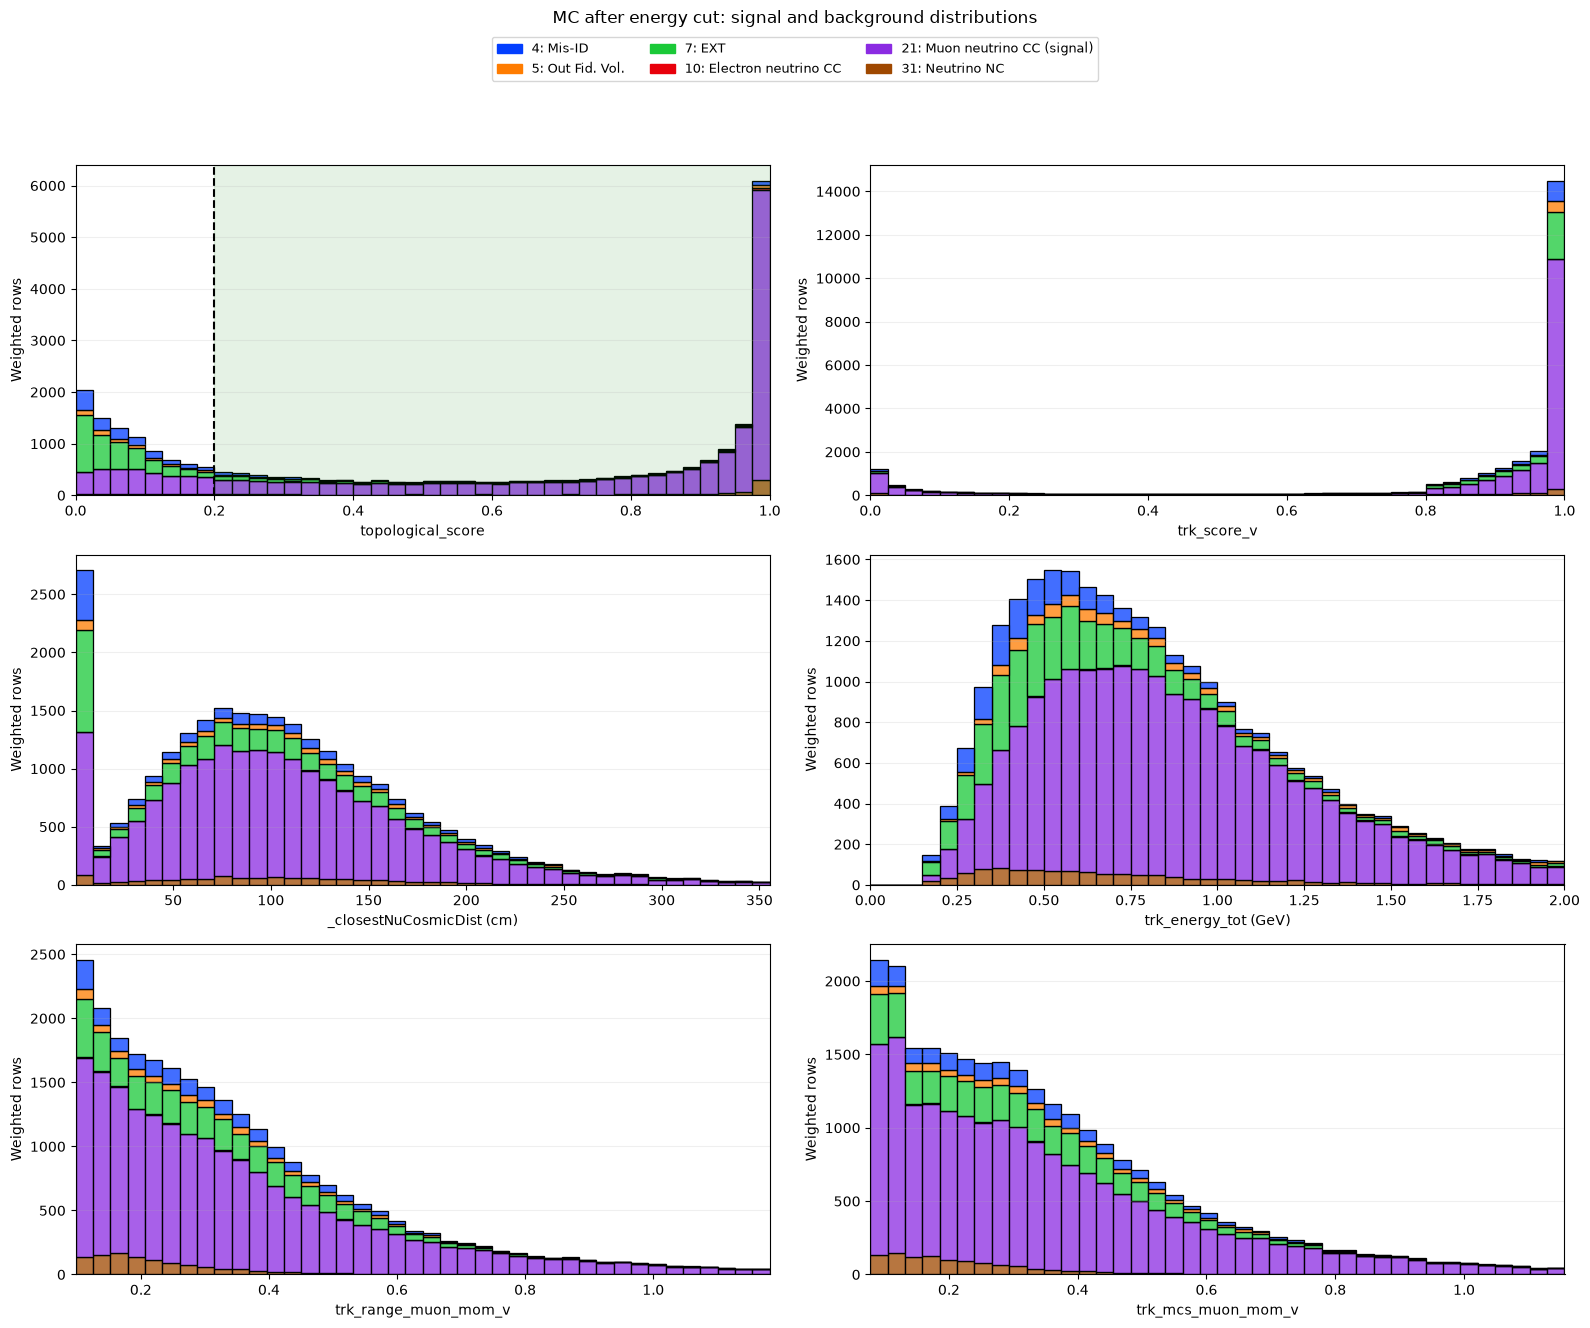

In [22]:
variables_to_plot = [
    'reco_nu_vtx_sce_x', 'reco_nu_vtx_sce_y', 'reco_nu_vtx_sce_z',
    'trk_sce_start_x_v', 'trk_sce_start_y_v', 'trk_sce_start_z_v',
    'trk_sce_end_x_v', 'trk_sce_end_y_v', 'trk_sce_end_z_v',
    'trk_len_v', 'trk_distance_v', 'trk_llr_pid_score_v',
    'topological_score', 'trk_score_v', '_closestNuCosmicDist',
    'trk_energy_tot', 'trk_range_muon_mom_v', 'trk_mcs_muon_mom_v'
]
display_ranges = {}
for variable in variables_to_plot:
    if variable.startswith(('reco_nu_vtx_sce_', 'trk_sce_start_', 'trk_sce_end_')):
        axis = variable[-1] if variable.startswith('reco_') else variable[-3]
        display_ranges[variable] = {'x': (-20, 280), 'y': (-140, 140), 'z': (-20, 1060)}[axis]
    elif variable in ['topological_score', 'trk_score_v']:
        display_ranges[variable] = (0, 1)
    elif variable == 'trk_llr_pid_score_v':
        display_ranges[variable] = (-1, 1)
    elif variable == 'trk_energy_tot':
        display_ranges[variable] = (0, energy_upper_cut)
    else:
        values = pd.to_numeric(MC_EXT_energy_selected[variable], errors='coerce')
        finite_values = values[np.isfinite(values)]
        display_ranges[variable] = tuple(finite_values.quantile([0.01, 0.99]))

proposed_ranges = {**fiducial_bounds,
                   'topological_score': (minimum_topological_score, None)}
for offset in range(0, len(variables_to_plot), 6):
    plot_category_histograms(
        MC_EXT_energy_selected, variables_to_plot[offset:offset+6],
        ranges=display_ranges, cut_ranges=proposed_ranges,
        title='MC after energy cut: signal and background distributions'
    )


### 3. Chosen cuts and physical interpretation

| Cut | Starting threshold | Reason and limitation |
|---|---|---|
| Reconstructed energy | `trk_energy_tot < 2 GeV` | Removes the high-energy tail outside the chosen analysis range, as suggested by the Labbook. Also removes genuine signal; efficiency must be reported. |
| Vertex x | `20 < x < 235 cm` | Removes edge regions; category 5 is more concentrated near x boundaries than signal. |
| Vertex y | `-100 < y < 100 cm` | Excludes top/bottom edge regions with a larger contribution from cosmic/EXT backgrounds. |
| Vertex z | `20 < z < 1000 cm` | A loose longitudinal interior requirement. The observed sample already has few rows in the excluded region, so this may add little rejection. |
| Topological score | `score > 0.20` | EXT and Mis-ID concentrate at low scores while much of category 21 lies higher. The overlap means this also loses signal. |

The coordinate bounds are analysis choices from the plotted populated region, not a claimed official MicroBooNE fiducial volume. PID, track score, length, vertex distance, cosmic distance, track endpoints and momentum distributions are inspected, but no extra thresholds are imposed without demonstrating a useful trade-off in Ex8. In particular, no lower energy threshold is added: keep the low-energy information for the later oscillation analysis.

The earlier random forest distinguished background categories only; its feature importance does not establish the best variables for signal selection.

In [23]:
def Selections(frame, return_cutflow=False):
    """Apply identical physical cuts to MC, data, and later closure samples.

    The optional cutflow contains row counts only; MC truth is never required.
    """
    energy = pd.to_numeric(frame['trk_energy_tot'], errors='coerce')
    conditions = [(f'Energy < {energy_upper_cut:g} GeV', np.isfinite(energy) & energy.lt(energy_upper_cut))]
    for variable, (lower, upper) in fiducial_bounds.items():
        values = pd.to_numeric(frame[variable], errors='coerce')
        conditions.append((f'{variable}: {lower:g} < value < {upper:g}',
                           np.isfinite(values) & values.gt(lower) & values.lt(upper)))
    score = pd.to_numeric(frame['topological_score'], errors='coerce')
    conditions.append((f'Topological score > {minimum_topological_score:g}',
                       np.isfinite(score) & score.gt(minimum_topological_score)))
    keep = pd.Series(True, index=frame.index)
    steps = [('Uncut', int(keep.sum()))]
    for label, condition in conditions:
        keep &= condition
        steps.append((label, int(keep.sum())))
    selected = frame.loc[keep].copy()
    cutflow = pd.DataFrame(steps, columns=['Selection', 'Rows'])
    return (selected, cutflow) if return_cutflow else selected

MC_EXT, mc_cutflow = Selections(MC_EXT_original, return_cutflow=True)
data_frame, data_cutflow = Selections(data_original, return_cutflow=True)
MC_EXT_cut_selected = MC_EXT.copy()
data_cut_selected = data_frame.copy()
selection_counts = mc_cutflow.rename(columns={'Rows': 'MC rows'}).merge(
    data_cutflow.rename(columns={'Rows': 'Data rows'}), on='Selection', validate='one_to_one'
)
print(selection_counts.to_string(index=False))


                            Selection  MC rows  Data rows
                                Uncut   555624     119970
                       Energy < 2 GeV   144211      28808
  reco_nu_vtx_sce_x: 20 < value < 235   131276      26355
reco_nu_vtx_sce_y: -100 < value < 100   119898      24097
 reco_nu_vtx_sce_z: 20 < value < 1000   119864      24090
              Topological score > 0.2    88703      16895


### 4. Check the resulting sample
Plot the same reconstructed-energy bins before and after the additional cuts. This is an MC selection check. The normalised MC/data comparison and uncertainty bands belong to Ex9.

For Ex8, retain both reference samples: use `MC_EXT_original` for efficiency relative to all original signal, or `MC_EXT_energy_selected` for efficiency conditional on the energy cut. Always state the denominator. The flattened dataframe counts rows, so row-based checks must not be described as unique-event efficiencies without verifying the event structure.

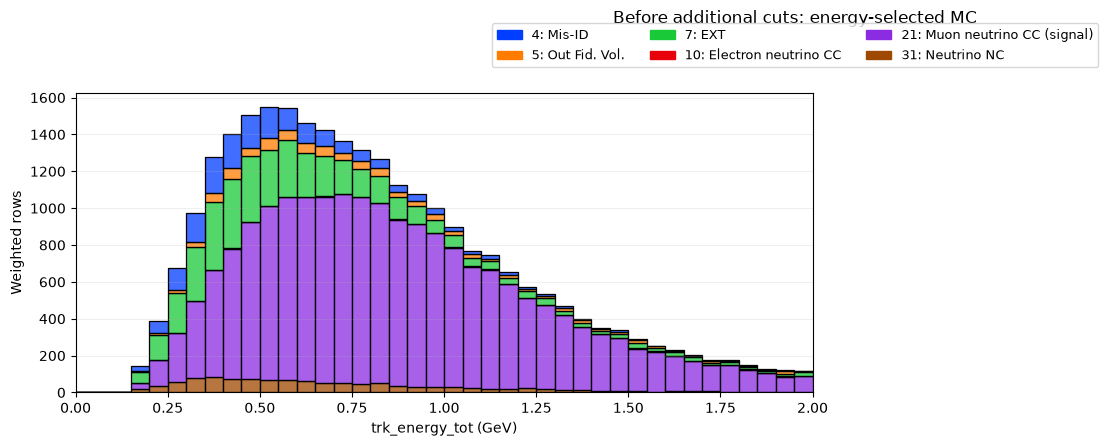

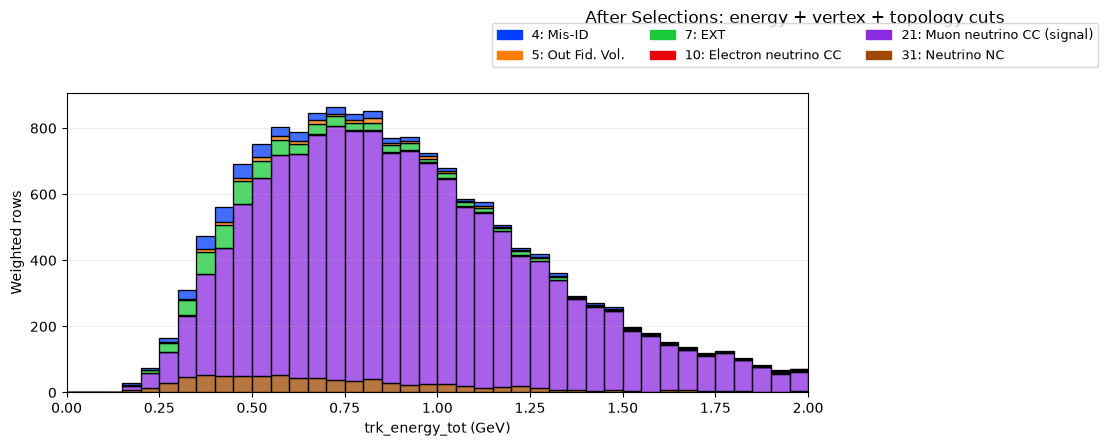

In [24]:
plot_category_histograms(
    MC_EXT_energy_selected, ['trk_energy_tot'],
    ranges={'trk_energy_tot': (0, energy_upper_cut)},
    title='Before additional cuts: energy-selected MC'
)
plot_category_histograms(
    MC_EXT, ['trk_energy_tot'],
    ranges={'trk_energy_tot': (0, energy_upper_cut)},
    title='After Selections: energy + vertex + topology cuts'
)


### Background confusion matrix after Selections
Optional diagnostic matching the earlier four-background matrix (categories 4, 5, 7 and 31). A separate random forest is trained on the selected MC, with natural class proportions and original feature units. Category 21 signal is not included, so this matrix measures background classification, not signal-selection efficiency or purity. Each row is normalised to one.

The split is by row; shared-event tracks may occur in both subsets. This is a within-sample diagnostic, not an independent validation of the cuts. Ex6 used different preprocessing, so its matrix is not a controlled before/after comparison.

Testing accuracy after Selections: 0.5674620390455531


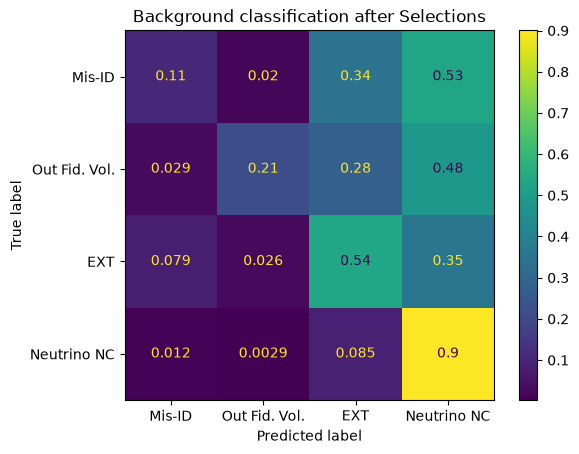

In [25]:
# Optional diagnostic: classify backgrounds remaining after all Ex7 cuts.
background_after_cuts = MC_EXT_cut_selected.loc[
    MC_EXT_cut_selected['category'].isin([4, 5, 7, 31])
].copy()
background_counts_after_cuts = background_after_cuts['category'].value_counts()
if set(background_counts_after_cuts.index) != {4, 5, 7, 31} or background_counts_after_cuts.min() < 2:
    raise ValueError('Too few rows in one or more background categories for a stratified split.')
x_train_after_cuts, x_test_after_cuts, y_train_after_cuts, y_test_after_cuts = train_test_split(
    background_after_cuts[features], background_after_cuts['category'].to_numpy(),
    test_size=0.2, random_state=1, stratify=background_after_cuts['category']
)
rf_after_cuts = RandomForestClassifier(
    random_state=1, n_estimators=1000, max_depth=8,
    min_samples_split=5, min_samples_leaf=2, criterion='gini', n_jobs=-1
)
rf_after_cuts.fit(x_train_after_cuts, y_train_after_cuts)
y_pred_after_cuts = rf_after_cuts.predict(x_test_after_cuts)
print('Testing accuracy after Selections:', metrics.accuracy_score(y_test_after_cuts, y_pred_after_cuts))
cm_after_cuts = confusion_matrix(
    y_test_after_cuts, y_pred_after_cuts, labels=[4, 5, 7, 31], normalize='true'
)
ConfusionMatrixDisplay(
    confusion_matrix=cm_after_cuts,
    display_labels=['Mis-ID', 'Out Fid. Vol.', 'EXT', 'Neutrino NC']
).plot()
plt.title('Background classification after Selections')
plt.show()


# Exercise 8: Check the purity and efficiency of the sample

For each Ex7 cut, calculate weighted signal (`category == 21`) and background (all other categories, including 10). Purity is `S / (S + B)`. Cumulative efficiency is `S / S_initial`, with the same uncut denominator at every stage. Step signal loss and background removal are relative to the preceding stage.

Use MC truth only; real data do not provide signal/background labels. Keep natural class proportions and physical weights. The flattened dataframe supports weighted-row checks here; unique-event efficiency needs a verified event identifier and event-level accounting. Run Ex7 before this section.

                   Stage   Rows Signal weight Background weight Purity Cumulative efficiency Step signal loss Step background removal
                   Uncut 555624       42354.7           67657.7  38.5%                100.0%             0.0%                    0.0%
          Energy < 2 GeV 144211       18971.5            8117.7  70.0%                 44.8%            55.2%                   88.0%
  Vertex x: 20 to 235 cm 131276       17405.9            7253.1  70.6%                 41.1%             8.3%                   10.7%
Vertex y: -100 to 100 cm 119898       16379.6            6041.4  73.1%                 38.7%             5.9%                   16.7%
 Vertex z: 20 to 1000 cm 119864       16378.7            6036.3  73.1%                 38.7%             0.0%                    0.1%
 Topological score > 0.2  88703       13730.4            2216.5  86.1%                 32.4%            16.2%                   63.3%


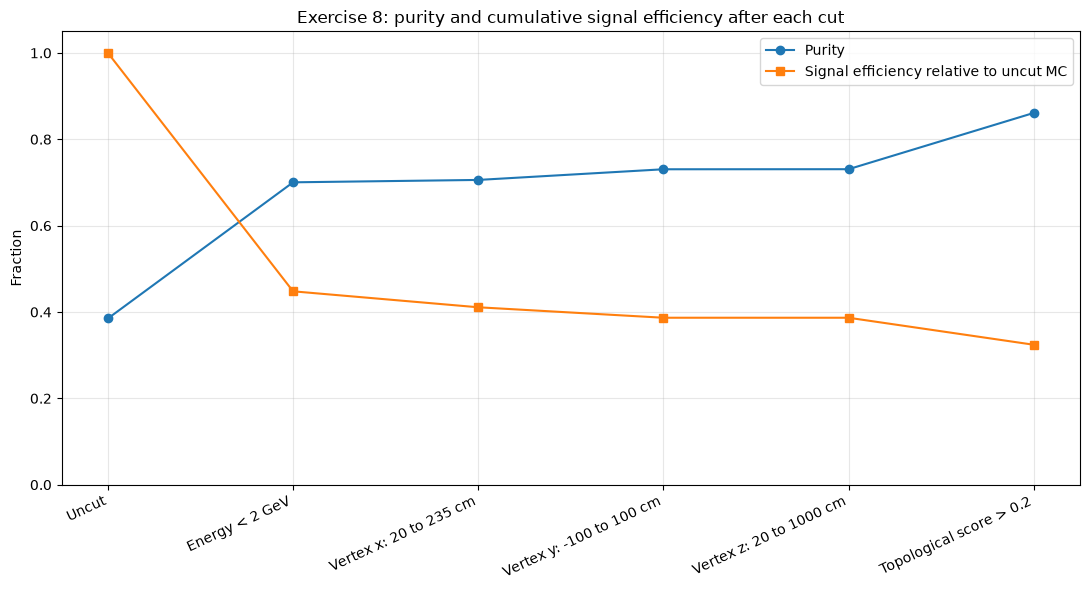

Final weighted-row purity: 86.1%
Final signal efficiency relative to uncut MC: 32.4%
Final signal efficiency relative to energy-selected MC: 72.4%
Largest fractional signal loss at one step: Energy < 2 GeV (55.2%)


In [26]:
# Run Ex7 first. Use uncut MC truth and original physical weights.
# These are weighted-row metrics, not verified unique-event efficiencies.
frame = MC_EXT_original
weights = pd.to_numeric(frame['weight'], errors='coerce')
if not np.isfinite(weights).all() or weights.lt(0).any():
    raise ValueError('This calculation requires finite, non-negative weights.')
signal = frame['category'].eq(21)
signal_initial = weights[signal].sum()
background_initial = weights[~signal].sum()
if signal_initial <= 0 or background_initial <= 0:
    raise ValueError('Positive initial signal and background yields are required.')

# Match the same thresholds and order as Ex7 Selections.
energy = pd.to_numeric(frame['trk_energy_tot'], errors='coerce')
cut_conditions = [(f'Energy < {energy_upper_cut:g} GeV',
                   np.isfinite(energy) & energy.lt(energy_upper_cut))]
for variable, (lower, upper) in fiducial_bounds.items():
    values = pd.to_numeric(frame[variable], errors='coerce')
    axis = variable[-1]
    cut_conditions.append((f'Vertex {axis}: {lower:g} to {upper:g} cm',
                           np.isfinite(values) & values.gt(lower) & values.lt(upper)))
score = pd.to_numeric(frame['topological_score'], errors='coerce')
cut_conditions.append((f'Topological score > {minimum_topological_score:g}',
                       np.isfinite(score) & score.gt(minimum_topological_score)))

keep = pd.Series(True, index=frame.index)
cutflow_rows = []
previous_signal = signal_initial
previous_background = background_initial

def record_selection(label, mask):
    global previous_signal, previous_background
    S = weights[mask & signal].sum()
    B = weights[mask & ~signal].sum()
    cutflow_rows.append({
        'Stage': label,
        'Rows': int(mask.sum()),
        'Signal weight': S,
        'Background weight': B,
        'Purity': S / (S + B) if S + B > 0 else np.nan,
        'Cumulative efficiency': S / signal_initial,
        'Step signal loss': 1 - S / previous_signal if previous_signal > 0 else np.nan,
        'Step background removal': 1 - B / previous_background if previous_background > 0 else np.nan
    })
    previous_signal, previous_background = S, B

record_selection('Uncut', keep)
for label, condition in cut_conditions:
    keep &= condition
    record_selection(label, keep)

# Catch any divergence between the audit and the actual Ex7 selection.
assert frame.loc[keep].equals(Selections(frame)), 'Cutflow does not match Ex7 Selections.'
cutflow_metrics = pd.DataFrame(cutflow_rows)
percent_columns = ['Purity', 'Cumulative efficiency', 'Step signal loss', 'Step background removal']
formatters = {column: '{:.1%}'.format for column in percent_columns}
formatters.update({'Signal weight': '{:.1f}'.format, 'Background weight': '{:.1f}'.format})
print(cutflow_metrics.to_string(index=False, formatters=formatters))

# The cumulative denominator is always the initial, uncut signal weight.
positions = np.arange(len(cutflow_metrics))
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(positions, cutflow_metrics['Purity'], 'o-', label='Purity')
ax.plot(positions, cutflow_metrics['Cumulative efficiency'], 's-',
        label='Signal efficiency relative to uncut MC')
ax.set_xticks(positions)
ax.set_xticklabels(cutflow_metrics['Stage'], rotation=25, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Fraction')
ax.set_title('Exercise 8: purity and cumulative signal efficiency after each cut')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Also quantify the additional cuts, keeping the reference explicit.
energy_signal = cutflow_metrics.iloc[1]['Signal weight']
final = cutflow_metrics.iloc[-1]
print(f"Final weighted-row purity: {final['Purity']:.1%}")
print(f"Final signal efficiency relative to uncut MC: {final['Cumulative efficiency']:.1%}")
if energy_signal > 0:
    print(f"Final signal efficiency relative to energy-selected MC: {final['Signal weight']/energy_signal:.1%}")
worst = cutflow_metrics.iloc[1:].sort_values('Step signal loss', ascending=False).iloc[0]
print(f"Largest fractional signal loss at one step: {worst['Stage']} ({worst['Step signal loss']:.1%})")


### Interpretation and next threshold checks

Read each row relative to the previous one. A useful cut removes background while retaining signal; a higher final purity alone does not prove a better selection. The contribution of a cut depends on its position in this sequence.

The energy threshold defines the selected analysis range and removes substantial signal. The additional vertex/topology cuts should therefore also be assessed relative to the energy-selected sample, with the denominator stated explicitly. The loose z cut has very little effect for this sample; its necessity can be revisited. The topology cut rejects low-score backgrounds but also loses signal.

These thresholds are starting choices. To optimise them, rerun Ex7 and this section after changing one threshold at a time, comparing the full table and the remaining energy spectrum. Preserve an independent MC validation sample before extensive tuning. This cutflow evaluates the current choice; it does not establish a unique optimum.

# Exercise 9: Plot the energy spectrums here and normalise

Final representation of MC and data after applying the cuts.

In [27]:
# Use identical energy bins for MC and real data
energy_bins = np.linspace(0, energy_upper_cut, 21)

# MC: calculate weighted counts in each energy bin
mc_counts, _ = np.histogram(
    MC_EXT['trk_energy_tot'],
    bins=energy_bins,
    weights=MC_EXT['weight']
)

# Real data: count each selected row once
data_counts, _ = np.histogram(
    data_frame['trk_energy_tot'],
    bins=energy_bins
)

# Calculate bin centres for plotting the data points
bin_centres = (energy_bins[:-1] + energy_bins[1:]) / 2

print('MC weighted counts:')
print(mc_counts)

print('\nData counts:')
print(data_counts)

MC weighted counts:
[   0.           28.15418156  240.25889179  783.64424153 1252.37856741
 1554.65318537 1634.77163101 1705.53925237 1620.19732207 1498.90595776
 1266.25141391 1083.46527333  854.70014623  654.93931839  530.00789683
  378.10365841  289.53206494  244.43344498  187.41709541  139.60439006]

Data counts:
[   0   32  256  813 1394 1724 1987 1867 1802 1629 1303 1068  782  577
  514  353  299  243  169   83]


In [28]:
# Calculate the MC statistical variance in each energy bin
mc_stat_variance, _ = np.histogram(
    MC_EXT['trk_energy_tot'],
    bins=energy_bins,
    weights=MC_EXT['weight'] ** 2
)

mc_stat_unc = np.sqrt(mc_stat_variance)

# Combine statistical and 15% systematic uncertainties in quadrature
mc_syst_unc = 0.15 * mc_counts
mc_total_unc = np.sqrt(mc_stat_unc**2 + mc_syst_unc**2)

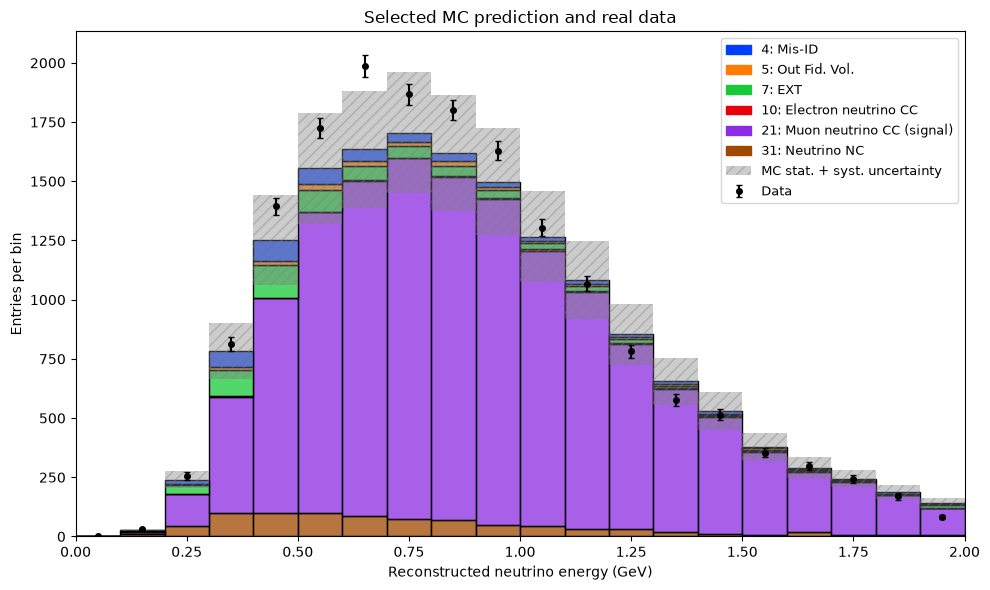

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the weighted MC contributions using the same energy bins
sns.histplot(
    data=MC_EXT,
    x='trk_energy_tot',
    hue='category',
    hue_order=category_order,
    palette=category_palette,
    weights='weight',
    multiple='stack',
    bins=energy_bins.tolist(),
    legend=False,
    ax=ax
)

# # Add a 15% systematic uncertainty band around the total MC prediction
# mc_syst_unc = 0.15 * mc_counts

# ax.stairs(
#     mc_counts + mc_syst_unc,
#     energy_bins,
#     baseline=mc_counts - mc_syst_unc,
#     fill=True,
#     facecolor='grey',
#     edgecolor='grey',
#     alpha=0.4,
#     hatch='///',
#     label='MC systematic uncertainty (15%)'
# )

# Show the combined MC statistical and systematic uncertainty
ax.stairs(
    mc_counts + mc_total_unc,
    energy_bins,
    baseline=mc_counts - mc_total_unc,
    fill=True,
    facecolor='grey',
    edgecolor='grey',
    alpha=0.4,
    hatch='///',
    label='MC stat. + syst. uncertainty'
)

# Overlay real data with approximate Poisson statistical uncertainties
ax.errorbar(
    bin_centres,
    data_counts,
    yerr=np.sqrt(data_counts),
    fmt='o',
    color='black',
    markersize=4,
    capsize=2,
    label='Data'
)

# Build a legend identifying each MC category
category_handles = [
    mpatches.Patch(
        color=category_palette[c],
        label=f'{c}: {category_names[c]}'
    )
    for c in category_order
]

overlay_handles, overlay_labels = ax.get_legend_handles_labels()
ax.legend(
    handles=category_handles + overlay_handles,
    labels=[h.get_label() for h in category_handles] + overlay_labels,
    fontsize=9
)

ax.set_xlabel('Reconstructed neutrino energy (GeV)')
ax.set_ylabel('Entries per bin')
ax.set_title('Selected MC prediction and real data')
ax.set_xlim(energy_bins[0], energy_bins[-1])
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

# Exercise 10: Oscillation and fitting

### a) Define functions requires for Oscillation analysis, test that they work!


In [30]:
# oscillation function
def survival_probability(E, dm2, sin2_2theta, L):

    E = np.asarray(E, dtype=float)

    if np.any(~np.isfinite(E)) or np.any(E <= 0):
        raise ValueError('Energy must be finite and positive.')
    if not 0 <= sin2_2theta <= 1:
        raise ValueError('sin2_2theta must lie between 0 and 1.')

    return 1 - sin2_2theta * np.sin(
        1.27 * dm2 * L / E
    )**2

In [31]:
# Apply disappearance using true energy, then plot reconstructed energy.
def apply_oscillation_to_mc(mc_frame, dm2, sin2_2theta, L=0.47):
    """Scale muon-neutrino CC signal weights; preserve backgrounds."""
    result = mc_frame.copy()
    signal = result['category'].eq(21)
    energy = result.loc[signal, 'true_E'].to_numpy(dtype=float)
    probability = survival_probability(energy, dm2, sin2_2theta, L)
    result['osc_weight'] = result['weight'].astype(float)
    result.loc[signal, 'osc_weight'] = (
        result.loc[signal, 'weight'].to_numpy() * probability
    )
    return result


In [32]:
# Use example parameters, not fitted values
MC_oscillated = apply_oscillation_to_mc(
    MC_EXT,
    dm2=1.0,
    sin2_2theta=0.5
)

# Inspect signal weights before and after oscillation
signal = MC_oscillated['category'].eq(21)

print(
    MC_oscillated.loc[
        signal,
        ['true_E', 'weight', 'osc_weight']
    ].head(10)
)

      true_E    weight  osc_weight
0   1.371928  0.000002    0.000002
1   1.371928  0.000002    0.000002
18  0.993030  0.186696    0.156840
25  0.741877  0.158957    0.117694
27  1.467931  0.158957    0.146524
28  1.467931  0.158957    0.146524
29  1.467931  0.158957    0.146524
33  1.321990  0.158957    0.143826
34  1.321990  0.158957    0.143826
35  1.321990  0.158957    0.143826


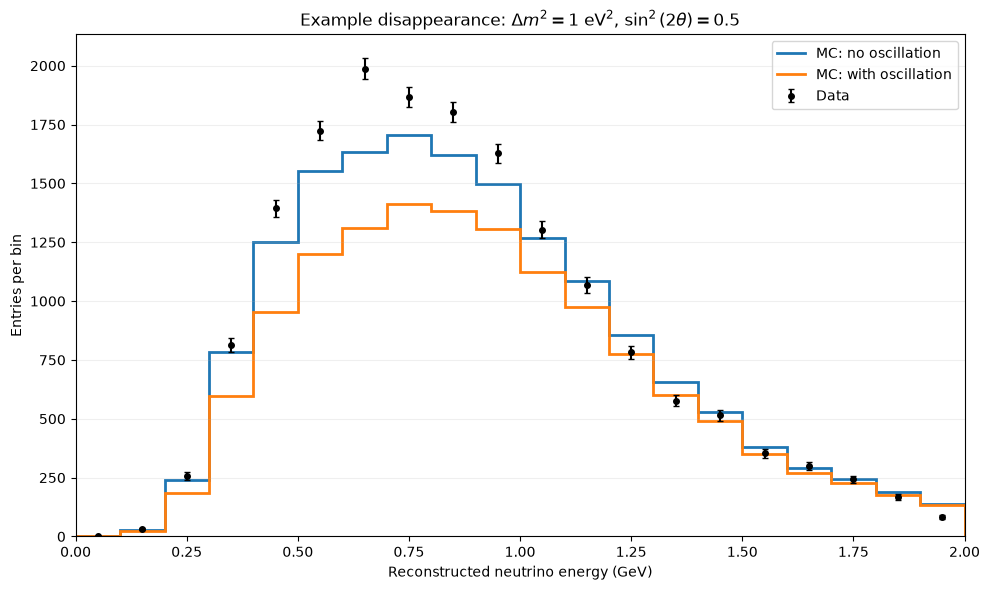

In [33]:
# Compare predictions using illustrative parameters, not fitted values.
example_dm2 = 1.0  # eV^2
example_amplitude = 0.5  # sin^2(2 theta)
MC_oscillated = apply_oscillation_to_mc(MC_EXT, example_dm2, example_amplitude)

# Use identical reconstructed-energy bins and retain physical normalisation.
mc_counts, _ = np.histogram(MC_EXT['trk_energy_tot'], bins=energy_bins,
                            weights=MC_EXT['weight'])
osc_counts, _ = np.histogram(MC_oscillated['trk_energy_tot'], bins=energy_bins,
                             weights=MC_oscillated['osc_weight'])
data_counts, _ = np.histogram(data_frame['trk_energy_tot'], bins=energy_bins)
bin_centres = (energy_bins[:-1] + energy_bins[1:]) / 2

fig, ax = plt.subplots(figsize=(10, 6))
ax.stairs(mc_counts, energy_bins, label='MC: no oscillation', linewidth=2)
ax.stairs(osc_counts, energy_bins, label='MC: with oscillation', linewidth=2)
ax.errorbar(bin_centres, data_counts, yerr=np.sqrt(data_counts),
            fmt='o', color='black', markersize=4, capsize=2, label='Data')
ax.set_xlabel('Reconstructed neutrino energy (GeV)')
ax.set_ylabel('Entries per bin')
ax.set_title(r'Example disappearance: $\Delta m^2=1$ eV$^2$, $\sin^2(2\theta)=0.5$')
ax.set_xlim(energy_bins[0], energy_bins[-1])
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()


In [34]:
# chi squared function
def chi_squared(observed, expected, uncertainty):
    """Calculate the chi-squared statistic for observed vs expected counts."""
    if len(observed) != len(expected) or len(observed) != len(uncertainty):
        raise ValueError('Observed, expected, and uncertainty arrays must have the same length.')
    if np.any(uncertainty <= 0):
        raise ValueError('Uncertainty values must be positive.')
    
    return np.sum(((observed - expected) ** 2) / (uncertainty ** 2))

In [35]:
# Test 1: identical spectra must give zero chi-squared
observed = np.array([10.0, 20.0, 30.0])
expected = np.array([10.0, 20.0, 30.0])
uncertainty = np.array([2.0, 4.0, 5.0])

assert np.isclose(
    chi_squared(observed, expected, uncertainty),
    0.0
)

# Test 2: a one-sigma difference in each bin gives chi-squared = 3
observed = expected + uncertainty

assert np.isclose(
    chi_squared(observed, expected, uncertainty),
    3.0
)

print('Chi-squared tests passed.')

Chi-squared tests passed.


In [36]:
# Use a fixed uncertainty model for this initial comparison
comparison_uncertainty = 0.15 * mc_counts

# Exclude bins empty in both predictions and data
empty_bins = (
    (mc_counts == 0)
    & (osc_counts == 0)
    & (data_counts == 0)
)

# Non-empty bins must have a positive uncertainty
valid_bins = ~empty_bins

if np.any(comparison_uncertainty[valid_bins] <= 0):
    raise ValueError(
        'A non-empty bin has zero uncertainty. Review the binning '
        'or uncertainty model.'
    )

chi2_no_oscillation = chi_squared(
    data_counts[valid_bins],
    mc_counts[valid_bins],
    comparison_uncertainty[valid_bins]
)

chi2_with_oscillation = chi_squared(
    data_counts[valid_bins],
    osc_counts[valid_bins],
    comparison_uncertainty[valid_bins]
)

print(f'No oscillation: chi-squared = {chi2_no_oscillation:.2f}')
print(f'With oscillation: chi-squared = {chi2_with_oscillation:.2f}')
print(f'Number of bins used: {valid_bins.sum()}')

No oscillation: chi-squared = 14.55
With oscillation: chi-squared = 44.37
Number of bins used: 19


# Exercise 11/12: Oscillation parameter scan, contour plotting, closure test.

### Closure test, create your oscillation parameter scanning code, and find minimum values for chi squared!

In [37]:
# Selection cuts on oscillated data
# Load the supplied closure-test sample; it already includes oscillation.
closure_file = './data/oscillated_data.pkl'
closure_original = pd.read_pickle(closure_file).drop(
    columns=['Subevent'], errors='ignore'
)

# Apply the same cuts used for MC and real data.
closure_selected = Selections(closure_original)

# Use the supplied weights; do not apply oscillation again to this sample.
closure_weights = pd.to_numeric(closure_selected['weight'], errors='coerce')
closure_energy = pd.to_numeric(closure_selected['trk_energy_tot'], errors='coerce')
if not np.isfinite(closure_weights).all() or not np.isfinite(closure_energy).all():
    raise ValueError('The selected closure sample contains non-finite energies or weights.')
closure_counts, _ = np.histogram(
    closure_energy,
    bins=energy_bins,
    weights=closure_weights
)

print(f'Closure-test rows before cuts: {len(closure_original):,}')
print(f'Closure-test rows after cuts: {len(closure_selected):,}')
print('Closure-test weighted spectrum:')
print(closure_counts)


Closure-test rows before cuts: 555,624
Closure-test rows after cuts: 88,703
Closure-test weighted spectrum:
[   0.           20.73526462  179.69085602  583.91465372  933.678194
 1116.61427231 1213.83771894 1200.63045013 1166.63760656 1129.79490686
  929.0264575   763.57877204  573.48172419  427.08647517  355.73509993
  264.47934175  207.4072152   179.19181826  140.24127312  102.74460317]


In [38]:
# Function that oscillates and calculates chi squared for set delM21 and sin^2(2theta)
def oscillation_chi_squared(mc_frame, target_counts, bins,
                           uncertainty, dm2, sin2_2theta):
    """Compare an oscillated MC prediction with a target spectrum."""

    # Convert spectrum inputs to numerical arrays
    target_counts = np.asarray(target_counts, dtype=float)
    uncertainty = np.asarray(uncertainty, dtype=float)

    # Apply trial oscillation parameters
    prediction = apply_oscillation_to_mc(
        mc_frame, dm2, sin2_2theta
    )

    # Build the predicted energy spectrum
    predicted_counts, _ = np.histogram(
        prediction['trk_energy_tot'],
        bins=bins,
        weights=prediction['osc_weight']
    )

    # Exclude bins with zero uncertainty only if both counts are zero
    empty = (
        (uncertainty == 0)
        & (predicted_counts == 0)
        & (target_counts == 0)
    )
    valid = ~empty

    return chi_squared(
        target_counts[valid],
        predicted_counts[valid],
        uncertainty[valid]
    )

# Test one parameter pair against the supplied closure-test spectrum.
closure_chi2_example = oscillation_chi_squared(
    mc_frame=MC_EXT,
    target_counts=closure_counts,
    bins=energy_bins,
    uncertainty=0.15 * mc_counts,
    dm2=1.0,
    sin2_2theta=0.5
)
print(f'Closure-test chi-squared (dm2=1.0, sin2_2theta=0.5): {closure_chi2_example:.4f}')


Closure-test chi-squared (dm2=1.0, sin2_2theta=0.5): 24.2562


In [39]:
# Function that loops the above function across range of values of delM21 and sin^2(2theta)
# Define the parameter grid
dm2_values = np.geomspace(0.0001, 50, 100)
amplitude_values = np.linspace(0.1, 1.0, 50)

# Rows: mixing amplitudes; columns: mass-squared differences
chi2_grid = np.empty((len(amplitude_values), len(dm2_values)))

# Keep uncertainties fixed throughout the scan
scan_uncertainty = 0.15 * mc_counts

for i, amplitude in enumerate(amplitude_values):
    for j, dm2 in enumerate(dm2_values):
        chi2_grid[i, j] = oscillation_chi_squared(
            mc_frame=MC_EXT,
            target_counts=closure_counts,
            bins=energy_bins,
            uncertainty=scan_uncertainty,
            dm2=dm2,
            sin2_2theta=amplitude
        )

print('Parameter scan completed.')

Parameter scan completed.


1 sigma: coverage = 68.2689%, delta chi-squared = 2.2957
2 sigma: coverage = 95.4500%, delta chi-squared = 6.1801
3 sigma: coverage = 99.7300%, delta chi-squared = 11.8292


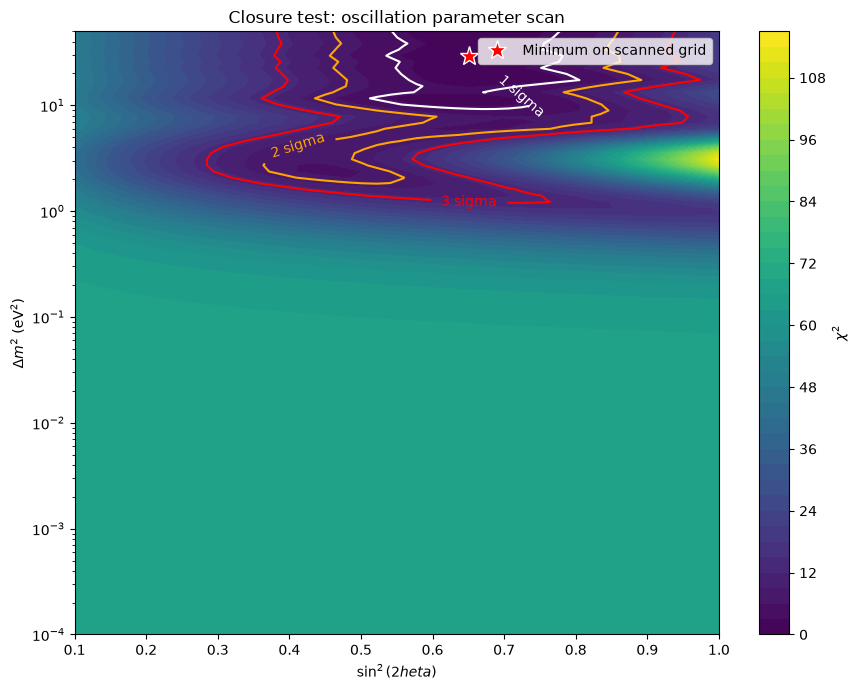

Minimum chi-squared on grid: 1.313103
Best grid value of delta m squared: 29.4245 eV^2
Best grid value of sin^2(2 theta): 0.65102
These are grid estimates. Refine the scan around the minimum before reporting final parameters.


In [40]:
# Plot the completed parameter scan and locate the grid minimum.
# Run the parameter-scan cell above first.
if chi2_grid.shape != (len(amplitude_values), len(dm2_values)):
    raise ValueError('Grid shape does not match the parameter arrays.')
if not np.isfinite(chi2_grid).all():
    raise ValueError('The chi-squared grid contains non-finite values.')

best_i, best_j = np.unravel_index(np.argmin(chi2_grid), chi2_grid.shape)
best_amplitude = amplitude_values[best_i]
best_dm2 = dm2_values[best_j]
minimum_chi2 = chi2_grid[best_i, best_j]

# Transpose the grid: x is amplitude, y is mass-squared difference.
fig, ax = plt.subplots(figsize=(9, 7))
filled = ax.contourf(
    amplitude_values, dm2_values, chi2_grid.T,
    levels=40, cmap='viridis'
)
fig.colorbar(filled, ax=ax, label=r'$\chi^2$')
ax.plot(best_amplitude, best_dm2, '*', color='red', markersize=14,
        markeredgecolor='white', label='Minimum on scanned grid')

# Calculate chi-squared differences from the grid minimum
delta_chi2 = chi2_grid - minimum_chi2

# Joint confidence contours for two fitted parameters

sigma_levels = np.array([1, 2, 3])
coverage = 2 * norm.cdf(sigma_levels) - 1
# Two jointly fitted parameters; asymptotic delta-chi-squared approximation.
confidence_levels = chi2.ppf(coverage, df=2)
confidence_labels = {
    float(level): f'{sigma} sigma'
    for sigma, level in zip(sigma_levels, confidence_levels)
}
for sigma, probability, threshold in zip(sigma_levels, coverage, confidence_levels):
    print(f'{sigma} sigma: coverage = {probability:.4%}, delta chi-squared = {threshold:.4f}')

contours = ax.contour(
    amplitude_values,
    dm2_values,
    delta_chi2.T,
    levels=confidence_levels,
    colors=['white', 'orange', 'red'],
    linewidths=1.5
)

ax.clabel(
    contours,
    fmt=confidence_labels,
    inline=True,
    fontsize=10
)

ax.set_yscale('log')
ax.set_xlabel(r'$\sin^2(2	heta)$')
ax.set_ylabel(r'$\Delta m^2$ (eV$^2$)')
ax.set_title('Closure test: oscillation parameter scan')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Minimum chi-squared on grid: {minimum_chi2:.6f}')
print(f'Best grid value of delta m squared: {best_dm2:.6g} eV^2')
print(f'Best grid value of sin^2(2 theta): {best_amplitude:.6g}')
if best_i in (0, len(amplitude_values)-1) or best_j in (0, len(dm2_values)-1):
    print('The minimum lies on a scan boundary; review the parameter range.')
print('These are grid estimates. Refine the scan around the minimum before reporting final parameters.')


Apply your above defined functions, and represent your result with matplotlib's contour and fcontour.

In [41]:
# oscillate MC wrt to true data
data_dm2_values = np.geomspace(0.0001, 50, 100)
amplitude_values = np.linspace(0.1, 1.0, 50)

# Rows: mixing amplitudes; columns: mass-squared differences
data_chi2_grid = np.empty((len(amplitude_values), len(data_dm2_values)))

# Keep uncertainties fixed throughout the scan
data_scan_uncertainty = 0.15 * mc_counts

for i, amplitude in enumerate(amplitude_values):
    for j, dm2 in enumerate(data_dm2_values):
        data_chi2_grid[i, j] = oscillation_chi_squared(
            mc_frame=MC_EXT,
            target_counts=data_counts,
            bins=energy_bins,
            uncertainty=data_scan_uncertainty,
            dm2=dm2,
            sin2_2theta=amplitude
        )

print('Real_data scan completed.')

Real_data scan completed.


1 sigma: coverage = 68.2689%, delta chi-squared = 2.2957
2 sigma: coverage = 95.4500%, delta chi-squared = 6.1801
3 sigma: coverage = 99.7300%, delta chi-squared = 11.8292


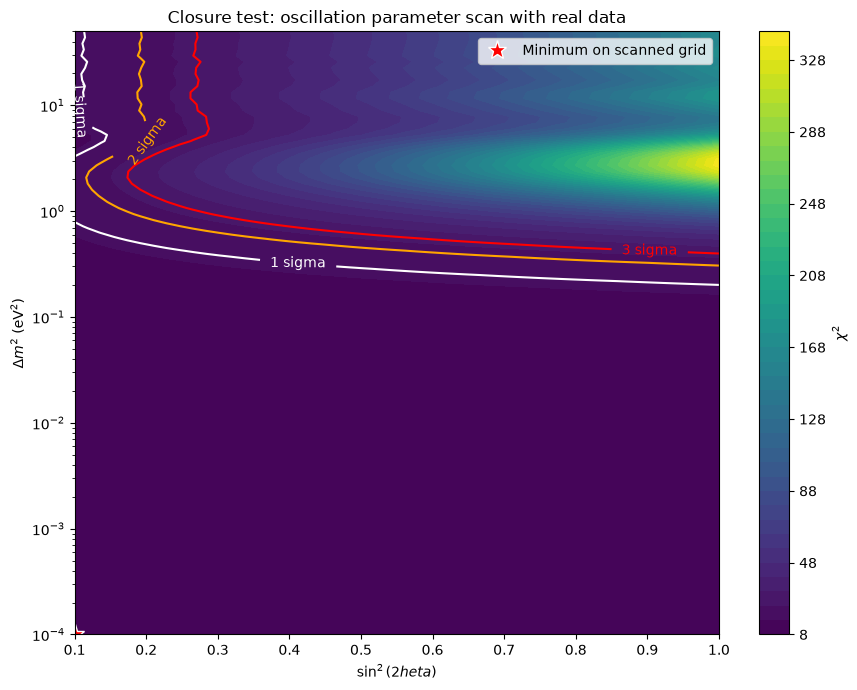

Minimum chi-squared on grid: 14.552922
Best grid value of delta m squared: 0.0001 eV^2
Best grid value of sin^2(2 theta): 0.1
The minimum lies on a scan boundary; review the parameter range.
These are grid estimates. Refine the scan around the minimum before reporting final parameters.


In [42]:
# contourf application
if data_chi2_grid.shape != (len(amplitude_values), len(data_dm2_values)):
    raise ValueError('Grid shape does not match the parameter arrays.')
if not np.isfinite(data_chi2_grid).all():
    raise ValueError('The chi-squared grid contains non-finite values.')

best_i, best_j = np.unravel_index(np.argmin(data_chi2_grid), data_chi2_grid.shape)
best_amplitude = amplitude_values[best_i]
best_dm2 = dm2_values[best_j]
minimum_chi2 = data_chi2_grid[best_i, best_j]

# Transpose the grid: x is amplitude, y is mass-squared difference.
fig, ax = plt.subplots(figsize=(9, 7))
filled = ax.contourf(
    amplitude_values, dm2_values, data_chi2_grid.T,
    levels=40, cmap='viridis'
)
fig.colorbar(filled, ax=ax, label=r'$\chi^2$')
ax.plot(best_amplitude, best_dm2, '*', color='red', markersize=14,
        markeredgecolor='white', label='Minimum on scanned grid')

# Calculate chi-squared differences from the grid minimum
delta_chi2 = data_chi2_grid - minimum_chi2

# Joint confidence contours for two fitted parameters

sigma_levels = np.array([1, 2, 3])
coverage = 2 * norm.cdf(sigma_levels) - 1
# Two jointly fitted parameters; asymptotic delta-chi-squared approximation.
confidence_levels = chi2.ppf(coverage, df=2)
confidence_labels = {
    float(level): f'{sigma} sigma'
    for sigma, level in zip(sigma_levels, confidence_levels)
}
for sigma, probability, threshold in zip(sigma_levels, coverage, confidence_levels):
    print(f'{sigma} sigma: coverage = {probability:.4%}, delta chi-squared = {threshold:.4f}')

contours = ax.contour(
    amplitude_values,
    dm2_values,
    delta_chi2.T,
    levels=confidence_levels,
    colors=['white', 'orange', 'red'],
    linewidths=1.5
)

ax.clabel(
    contours,
    fmt=confidence_labels,
    inline=True,
    fontsize=10
)

ax.set_yscale('log')
ax.set_xlabel(r'$\sin^2(2	heta)$')
ax.set_ylabel(r'$\Delta m^2$ (eV$^2$)')
ax.set_title('Closure test: oscillation parameter scan with real data')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Minimum chi-squared on grid: {minimum_chi2:.6f}')
print(f'Best grid value of delta m squared: {best_dm2:.6g} eV^2')
print(f'Best grid value of sin^2(2 theta): {best_amplitude:.6g}')
if best_i in (0, len(amplitude_values)-1) or best_j in (0, len(dm2_values)-1):
    print('The minimum lies on a scan boundary; review the parameter range.')
print('These are grid estimates. Refine the scan around the minimum before reporting final parameters.')


### Bonus: Minimise

Minimise your chi square value, determining the parameters of 'best fit'

In [43]:
from scipy.optimize import minimize

# Return chi-squared for a trial parameter pair
def objective(parameters):
    dm2, amplitude = parameters

    return oscillation_chi_squared(
        mc_frame=MC_EXT,
        target_counts=data_counts,
        bins=energy_bins,
        uncertainty=data_scan_uncertainty,
        dm2=dm2,
        sin2_2theta=amplitude
    )

# Find the best point from the completed real-data scan.
# The scan above uses amplitude_values, not data_amplitude_values.
if data_chi2_grid.shape != (len(amplitude_values), len(data_dm2_values)):
    raise ValueError('The real-data grid does not match the parameter arrays.')
if not np.isfinite(data_chi2_grid).all():
    raise ValueError('The real-data grid contains non-finite values.')
data_best_i, data_best_j = np.unravel_index(
    np.argmin(data_chi2_grid), data_chi2_grid.shape
)
data_best_dm2 = data_dm2_values[data_best_j]
data_best_amplitude = amplitude_values[data_best_i]

# Start from the best point found by the grid scan
fit_result = minimize(
    objective,
    x0=[data_best_dm2, data_best_amplitude],
    method='L-BFGS-B',
    bounds=[
        (data_dm2_values.min(), data_dm2_values.max()),
        (0.0, 1.0)
    ]
)

print('Optimisation successful:', fit_result.success)
print('Message:', fit_result.message)
print(f'Minimum chi-squared: {fit_result.fun:.6f}')
print(f'Delta m squared: {fit_result.x[0]:.6g} eV^2')
print(f'sin^2(2 theta): {fit_result.x[1]:.6g}')

Optimisation successful: True
Message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Minimum chi-squared: 14.552922
Delta m squared: 0.0001 eV^2
sin^2(2 theta): 0.1


### Confidence levels and parameter minima. 
Determine confidence levels, and find the parameter values that correspond to the lowest chi squared value within your range.with

In [44]:
# contour application, with correct confidence levels.

In [45]:
# find lowest chi squared value within range and plot with CL, or contourf plot.

# Exercise 13/14: 3+1 Framework Neutrino disappearance.

In [46]:
# Produce your new oscillation parameter, which should be sin^2(2*theta_ue)

# Compare your result with MiniBooNE

Results are extracted from MiniBooNE (orange) and LSND (blue)

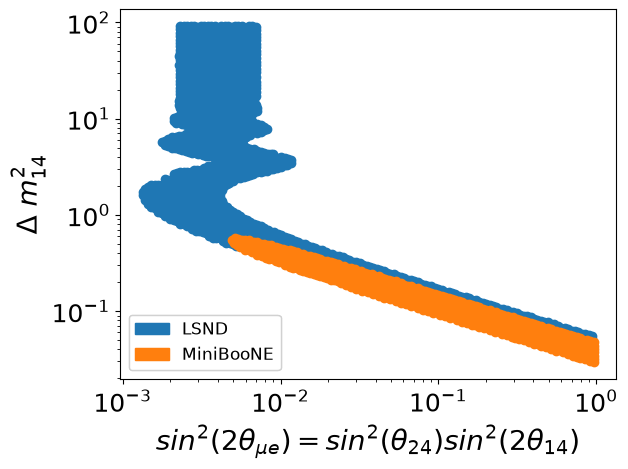

In [47]:
# Load data
LSND_data = pd.read_csv('./data/DataSet_LSND.csv').to_numpy()
MiniBooNE_data = pd.read_csv('./data/DataSet_MiniBooNE.csv').to_numpy()

# Plot data
plt.plot(LSND_data[:,0],LSND_data[:,1],'o')
plt.plot(MiniBooNE_data[:,0],MiniBooNE_data[:,1],'o')

# Producing MiniBooNE/LSND legend
LSND_path = mpatches.Patch(color='tab:blue', label = 'LSND')
MINI_path = mpatches.Patch(color='tab:orange', label = 'MiniBooNE')
first_legend = plt.legend(handles=[LSND_path, MINI_path], loc = 'lower left', fontsize = 12)
plt.gca().add_artist(first_legend)


plt.xlabel(r'$sin^2(2\theta_{\mu e})=sin^2(\theta_{24})sin^2(2\theta_{14})$',fontsize=20)
plt.ylabel(r'$\Delta$ $m_{14}^2$',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.yscale('log')
plt.xscale('log')
plt.show()